# TP2 : Transfer Learning et Apprentissage Multitâche
## EXERCICE 3 : Apprentissage multitâche — Catalogue e-commerce (Fashion-MNIST)

Exécuter avec **« Redémarrer et tout exécuter »** (les cellules doivent être exécutées dans l'ordre). Durée indicative sur GPU Colab : 40 à 60 min (balayage de λ_B sur 5 graines et régime à 3 000 images sur 5 graines). Les résultats sont exportés dans `figures/results_ex3.json`.

**Règles méthodologiques de cette version :** (1) le choix de λ_B se fait sur la **validation**, jamais sur le test ; (2) mono-tâche et multitâche sont comparés **graine par graine** (différences appariées) avec intervalle de confiance et test ; (3) les écarts de quelques dixièmes de point ne sont pas interprétés sans test (1 point d'accuracy = 100 images sur les 10 000 images de test ; IC95 d'une accuracy ≈ ±0,55 pt).

# Cellule 1 — Importation des bibilothèques necessaires

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from IPython.display import display, Image
import time
import os
import random

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 128
EPOCHS = 15

print("TensorFlow version:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

import json, gc
from scipy import stats
os.makedirs('figures', exist_ok=True)
RESULTS = {}   # exporté en figures/results_ex3.json en fin de notebook


TensorFlow version: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Cellule 2 — Données, split stratifié, mapping famille

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train_full = x_train_full[..., np.newaxis]
x_test = x_test[..., np.newaxis]

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Mapping catégorie -> famille (code de démarrage du PDF, respecté strictement)
famille = np.array([0, 1, 0, 1, 0, 2, 0, 2, 3, 2])
family_names = ["Hauts", "Bas et robes", "Chaussures", "Accessoires"]

def to_famille(y_cat):
    return famille[y_cat]

y_train_full_fam = to_famille(y_train_full)
y_test_fam = to_famille(y_test)

# Split stratifié (sur la catégorie fine -> stratifie aussi implicitement la famille)
x_train, x_val, y_train, y_val, y_train_fam, y_val_fam = train_test_split(
    x_train_full, y_train_full, y_train_full_fam,
    test_size=0.2, random_state=SEED, stratify=y_train_full
)

print("Train :", x_train.shape, " Val :", x_val.shape, " Test :", x_test.shape)

# Matrice d'agrégation catégorie -> famille (10x4, one-hot), utile pour la loss hiérarchique
FAMILY_MATRIX = np.zeros((10, 4), dtype="float32")
for cat, fam in enumerate(famille):
    FAMILY_MATRIX[cat, fam] = 1.0

print("\nMatrice d'agrégation catégorie->famille :\n", FAMILY_MATRIX)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : (48000, 28, 28, 1)  Val : (12000, 28, 28, 1)  Test : (10000, 28, 28, 1)

Matrice d'agrégation catégorie->famille :
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


# Cellule 3 — Visualisations

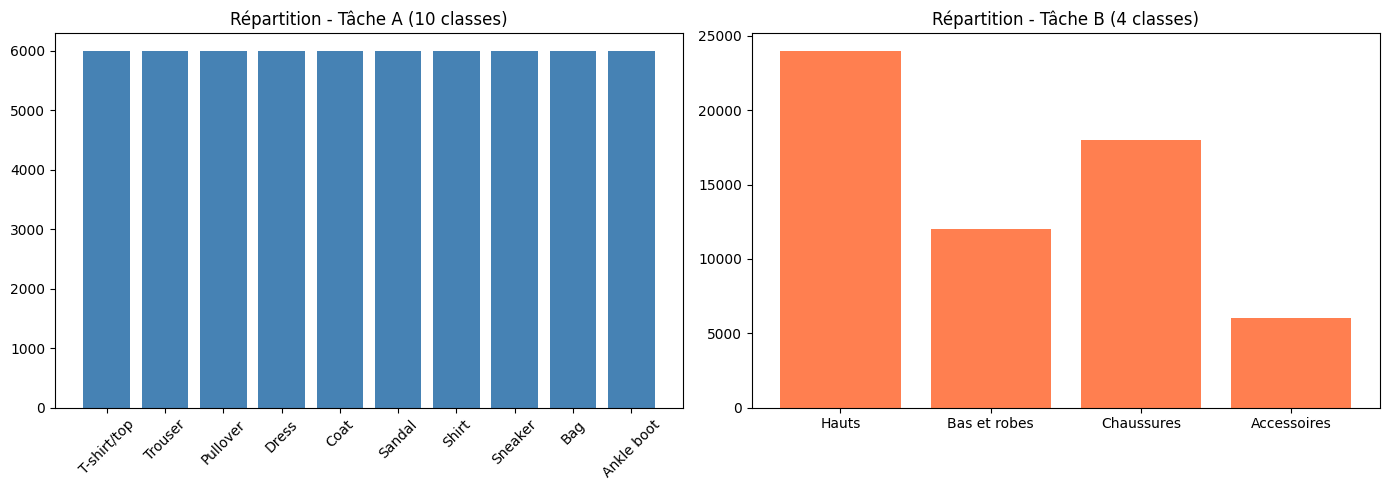

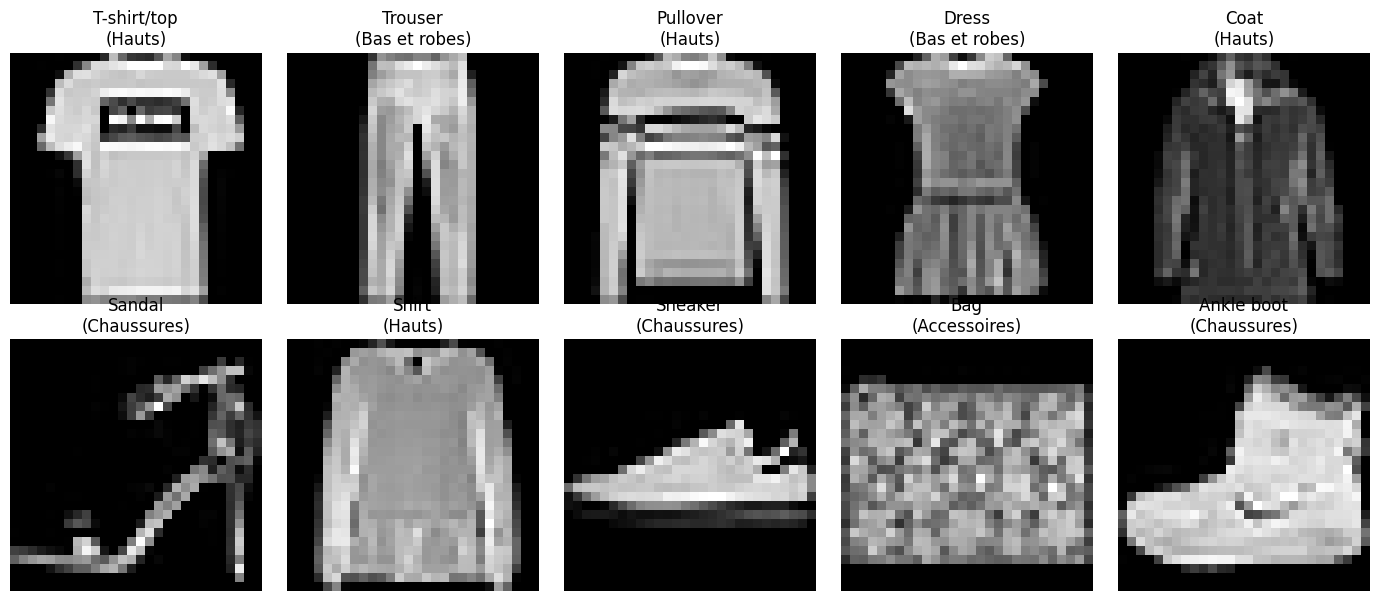

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_counts = pd.Series(y_train_full).value_counts().sort_index()
axes[0].bar([class_names[i] for i in cat_counts.index], cat_counts.values, color="steelblue")
axes[0].set_title("Répartition - Tâche A (10 classes)")
axes[0].tick_params(axis='x', rotation=45)

fam_counts = pd.Series(y_train_full_fam).value_counts().sort_index()
axes[1].bar([family_names[i] for i in fam_counts.index], fam_counts.values, color="coral")
axes[1].set_title("Répartition - Tâche B (4 classes)")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == i)[0][0]
    ax.imshow(x_train_full[idx].squeeze(), cmap="gray")
    ax.set_title(f"{class_names[i]}\n({family_names[famille[i]]})")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Cellule 4 — Pipeline tf.data

In [4]:
def make_dataset(x, y, batch_size=BATCH_SIZE, shuffle=False, augment=False, seed=SEED):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    # Mélange (shuffle) si activé
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(x), 10000), seed=seed,
                            reshuffle_each_iteration=True)
    if augment:
        def _augment(img, label):
            img = tf.image.random_flip_left_right(img)
            return img, label
        ds = ds.map(_augment, num_parallel_calls=AUTOTUNE)
    # Groupement par batch et optimisation des performances (prefetch)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

# Cellule 5 — Backbone convolutif partagé (+ fix BN momentum)

Cette cellule définit la fonction `build_conv_backbone`, qui construit l'architecture du réseau de neurones convolutif (CNN) servant d'extracteur de caractéristiques (backbone) partagé.

####  Rôle et structure des couches :
* **Blocs Convolutifs progressifs (3 niveaux) :**
  * Niveau 1 : Convolution 2D (`32` filtres, noyau `3x3`, padding `same`, ReLU) + Batch Normalization + MaxPooling.
  * Niveau 2 : Convolution 2D (`64` filtres, noyau `3x3`, padding `same`, ReLU) + Batch Normalization + MaxPooling.
  * Niveau 3 : Convolution 2D (`128` filtres, noyau `3x3`, padding `same`, ReLU) + Batch Normalization + **Global Average Pooling 2D**.
* **Fix du BN Momentum (`bn_momentum=0.9`) :** L'argument `bn_momentum` est passé explicitement aux couches `BatchNormalization` pour stabiliser l'apprentissage et l'actualisation des moyennes mobiles (très utile pour éviter l'instabilité, notamment lors du fine-tuning ou avec des tailles de batch spécifiques).
* **Couches Dense et Régularisation :**
  * Une couche `Dense` de `128` neurones avec activation ReLU pour projeter les caractéristiques extraites dans un espace latent dense.
  * Un `Dropout` de `0.3` (désactivation aléatoire de 30% des neurones) pour prévenir le surapprentissage (*overfitting*).

In [5]:
def build_conv_backbone(inputs, bn_momentum=0.9):
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization(momentum=bn_momentum)(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    return x

# Cellule 6 — DualTaskEarlyStopping

Cette cellule définit un callback Keras sur mesure (`DualTaskEarlyStopping`) conçu pour piloter l'apprentissage d'un modèle à **double tâche** (multi-task learning).

####  Fonctionnement clé :
* **Score combiné :** Calcule une moyenne pondérée de deux métriques de validation distinctes (`wa * acc_a + wb * acc_b`) pour évaluer la performance globale du modèle à chaque époque.
* **Suivi et sauvegarde automatique :** Conserve en mémoire les poids du modèle correspondant au meilleur score combiné rencontré.
* **Gestion de la patience :** Interrompt l'entraînement si le score combiné ne s'améliore plus pendant un nombre d'époques défini (`patience`).
* **Restauration garantie (`on_train_end`) :** Réapplique automatiquement les meilleurs poids trouvés à la fin de l'entraînement, qu'il y ait eu arrêt anticipé ou non.

In [6]:
class DualTaskEarlyStopping(keras.callbacks.Callback):
    def __init__(self, wa=0.5, wb=0.5, patience=5,
                 monitor_a="val_categorie_accuracy",
                 monitor_b="val_famille_accuracy",
                 verbose=1):
        super().__init__()
        self.wa, self.wb = wa, wb
        self.monitor_a, self.monitor_b = monitor_a, monitor_b
        self.patience = patience
        self.verbose = verbose
    def on_train_begin(self, logs=None):
        # Initialisation des variables de suivi au début de l'entraînement
        self.wait = 0
        self.best_score = -np.inf
        self.best_epoch = -1
        self.best_weights = None
        self.stopped_epoch = 0
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        acc_a = logs.get(self.monitor_a)
        acc_b = logs.get(self.monitor_b)
        if acc_a is None or acc_b is None:
            return
        score = self.wa * acc_a + self.wb * acc_b  # Calcul du score combiné pondéré des deux tâches
        if score > self.best_score:
            self.best_score = score
            self.best_epoch = epoch
            self.best_weights = self.model.get_weights()
            self.wait = 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.stopped_epoch = epoch
                self.model.stop_training = True

    def on_train_end(self, logs=None):
        # FIX CRITIQUE : restauration inconditionnelle
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)
            if self.verbose:
                total_epochs = self.params.get("epochs", "?")
                if self.stopped_epoch > 0:
                    print(f"[DualTaskEarlyStopping] Arrêt anticipé à l'époque "
                          f"{self.stopped_epoch + 1}, restauration des poids de "
                          f"l'époque {self.best_epoch + 1} "
                          f"(score combiné={self.best_score:.4f})")
                else:
                    print(f"[DualTaskEarlyStopping] {total_epochs} époques "
                          f"atteintes sans arrêt anticipé -> restauration "
                          f"forcée des meilleurs poids trouvés à l'époque "
                          f"{self.best_epoch + 1} "
                          f"(score combiné={self.best_score:.4f})")

# Cellule 7 — Mesure de latence rigoureuse

Cette cellule définit la fonction `measure_latency_rigorous`, conçue pour évaluer précisément les performances temporelles d'un modèle en conditions réelles.

####  Fonctionnalités clés :
* **Appel direct (`model()`) :** Contourne les surcoûts liés aux files d'attente et aux vérifications internes de la méthode standard `model.predict()`.
* **Phase de chauffe (*Warm-up*) :** Exécute un nombre défini d'inférences initiales (`n_warmup`) non mesurées pour stabiliser le cache, l'optimisation JIT et l'initialisation du matériel (CPU/GPU).
* **Synchronisation stricte (`.numpy()`) :** Force l'évaluation complète des résultats (qu'il s'agisse de tenseurs uniques ou de dictionnaires de sorties multi-tâches) pour s'assurer que le chronomètre mesure bien la fin effective des calculs.
* **Statistiques détaillées :** Calcule et retourne un dictionnaire de métriques (moyenne, écart-type, médiane, min, max) exprimées en millisecondes par échantillon (`ms/sample`).

In [7]:
def measure_latency_rigorous(model, x_sample, n_warmup=20, n_runs=200, batch_size=1):
    """Mesure de latence via model() direct, sans overhead de predict()."""
    x_batch = tf.constant(x_sample[:batch_size])
    # Phase de chauffe pour stabiliser le cache et le matériel
    for _ in range(n_warmup):
        out = model(x_batch, training=False)
        if isinstance(out, dict):
            for v in out.values():
                _ = v.numpy()
        else:
            _ = out.numpy()
    times = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        out = model(x_batch, training=False)
        if isinstance(out, dict):
            for v in out.values():
                _ = v.numpy()
        else:
            _ = out.numpy()
        t1 = time.perf_counter()
        times.append((t1 - t0) * 1000.0 / batch_size)

    times = np.array(times)
    return {"mean": times.mean(), "std": times.std(), "median": np.median(times),
            "min": times.min(), "max": times.max()}

# Cellule 8 — Mono-tâches A et B ( restore_best_weights=True)

Cette cellule construit, entraîne et évalue séparément deux modèles mono-tâches distincts basés sur le même backbone convolutif :
* **Modèle A :** Classification fine (10 classes).
* **Modèle B :** Classification par famille (4 classes).

####  Fonctionnalités clés :
* **Construction modulaire :** Utilise la fonction `build_single_task_model` pour injecter le backbone partagé et adapter la couche de sortie (`Dense`) au nombre de classes de chaque tâche.
* **Sécurisation de l'entraînement :** Intègre un `EarlyStopping` avec `restore_best_weights=True` pour éviter le surapprentissage et conserver automatiquement les meilleurs poids de l'époque optimale.
* **Analyse comparative des performances :** Extrait le meilleur score de validation, mesure la précision réelle sur le jeu de test (`evaluate`), et calcule l'écart de généralisation (`val_accuracy` vs `test_accuracy`).

In [8]:
def build_single_task_model(num_classes, name, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="image")
    x = build_conv_backbone(inputs)
    # Couche de sortie softmax pour la classification multi-classes
    outputs = layers.Dense(num_classes, activation="softmax", name=name)(x)
    model = keras.Model(inputs, outputs, name=f"model_{name}")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train_single_task(model, x_tr, y_tr, x_va, y_va, epochs=EPOCHS,
                       batch_size=BATCH_SIZE, verbose=1):
    train_ds = make_dataset(x_tr, y_tr, batch_size=batch_size, shuffle=True, augment=False)
    val_ds = make_dataset(x_va, y_va, batch_size=batch_size, shuffle=False, augment=False)
    # Callback d'arrêt anticipé pour stopper l'entraînement si la validation stagne
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=4, mode="max",
            restore_best_weights=True,   # Restaure automatiquement les meilleurs poids trouvés
            verbose=verbose
        )
    ]
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                      callbacks=callbacks, verbose=verbose)

print("=" * 60)
print("MONO-TÂCHE A : Catégorie fine (10 classes)")
print("=" * 60)
model_a = build_single_task_model(10, "categorie", lr=1e-3)
history_a = train_single_task(model_a, x_train, y_train, x_val, y_val)

test_ds_a = make_dataset(x_test, y_test, batch_size=BATCH_SIZE, shuffle=False)
loss_a, acc_a = model_a.evaluate(test_ds_a, verbose=0)
best_epoch_a = int(np.argmax(history_a.history["val_accuracy"]))
best_val_a = history_a.history["val_accuracy"][best_epoch_a]
print(f"\nAccuracy test - Mono A : {acc_a:.4f}")
print(f"Meilleur val_accuracy : {best_val_a:.4f} (époque {best_epoch_a+1})")
print(f"Écart meilleur val / test : {best_val_a - acc_a:.4f}")

print("\n" + "=" * 60)
print("MONO-TÂCHE B : Famille (4 classes)")
print("=" * 60)
model_b = build_single_task_model(4, "famille", lr=1e-3)
history_b = train_single_task(model_b, x_train, y_train_fam, x_val, y_val_fam)

test_ds_b = make_dataset(x_test, y_test_fam, batch_size=BATCH_SIZE, shuffle=False)
loss_b, acc_b = model_b.evaluate(test_ds_b, verbose=0)
best_epoch_b = int(np.argmax(history_b.history["val_accuracy"]))
best_val_b = history_b.history["val_accuracy"][best_epoch_b]
print(f"\nAccuracy test - Mono B : {acc_b:.4f}")
print(f"Meilleur val_accuracy : {best_val_b:.4f} (époque {best_epoch_b+1})")
print(f"Écart meilleur val / test : {best_val_b - acc_b:.4f}")

MONO-TÂCHE A : Catégorie fine (10 classes)
Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.8109 - loss: 0.5389 - val_accuracy: 0.8714 - val_loss: 0.3641
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8872 - loss: 0.3148 - val_accuracy: 0.8856 - val_loss: 0.3068
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9070 - loss: 0.2596 - val_accuracy: 0.8947 - val_loss: 0.2854
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9165 - loss: 0.2330 - val_accuracy: 0.9107 - val_loss: 0.2404
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9263 - loss: 0.2076 - val_accuracy: 0.9181 - val_loss: 0.2303
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9323 - loss: 0.1899 - val_accuracy: 0.9117 - val_loss: 0.2451
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9376 - loss: 0.1734 - val_accuracy: 0.9181 - val_loss: 0.2246
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accu

# Cellule 9 — Courbes mono-tâche + gap d'overfitting

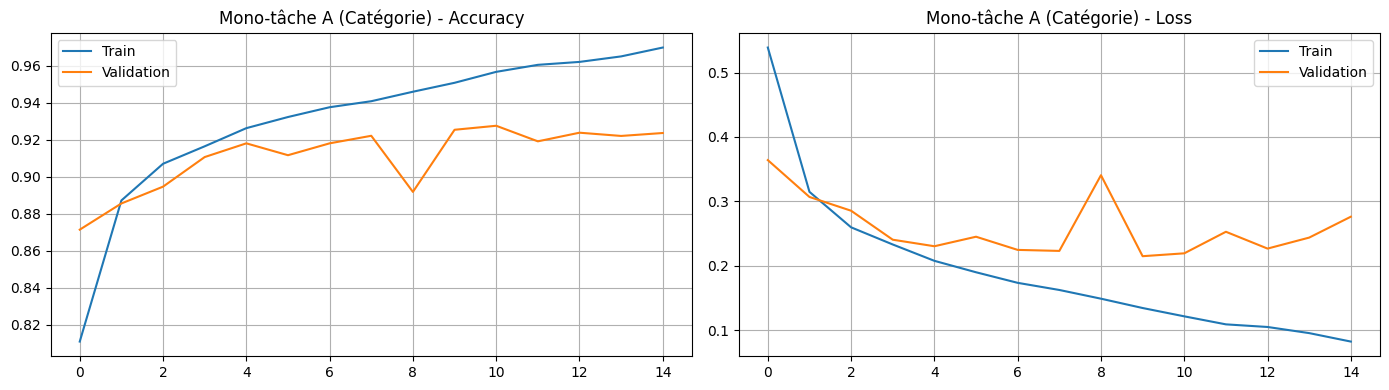

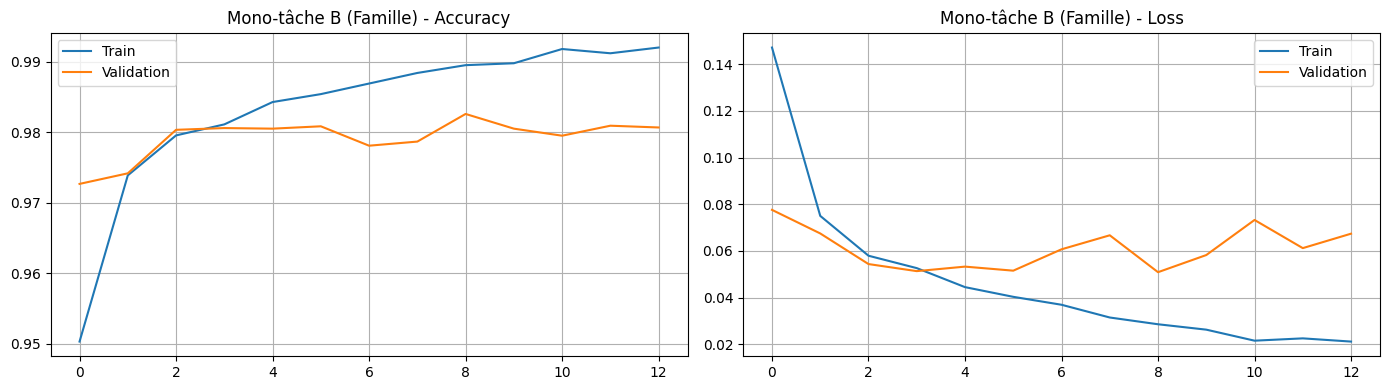

Gap train-val (overfitting) - Modèle A : 2.9 pts
Gap train-val (overfitting) - Modèle B : 0.7 pts


In [9]:
def plot_history_single(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title(f"{title} - Accuracy")
    axes[0].legend(); axes[0].grid(True)

    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title(f"{title} - Loss")
    axes[1].legend(); axes[1].grid(True)
    plt.tight_layout()
    plt.show()

plot_history_single(history_a, "Mono-tâche A (Catégorie)")
plot_history_single(history_b, "Mono-tâche B (Famille)")

gap_a = (history_a.history["accuracy"][best_epoch_a] - history_a.history["val_accuracy"][best_epoch_a]) * 100
gap_b = (history_b.history["accuracy"][best_epoch_b] - history_b.history["val_accuracy"][best_epoch_b]) * 100
print(f"Gap train-val (overfitting) - Modèle A : {gap_a:.1f} pts")
print(f"Gap train-val (overfitting) - Modèle B : {gap_b:.1f} pts")

# Cellule 10 — Loss hiérarchique

Cette cellule définit la classe `CoherenceLoss`, une couche Keras sur mesure qui pénalise l'incohérence entre les prédictions de catégories fines (`p_cat`) et les prédictions de familles larges (`p_fam`).

####  Fonctionnalités clés :
* **Projection hiérarchique (`tf.matmul`) :** Utilise une matrice de correspondance (`FAMILY_MATRIX_TF`) pour déduire les probabilités de familles directement à partir des probabilités de catégories.
* **Stabilité numérique (`tf.clip_by_value`) :** Empêche les valeurs proches de zéro d'engendrer des erreurs mathématiques lors du calcul du logarithme.
* **Divergence de Kullback-Leibler (KL) :** Mesure la distance (l'écart) entre la distribution de famille déduite des catégories et la distribution de famille prédite par le modèle.
* **Intégration automatique (`self.add_loss`) :** Injecte la perte de cohérence pondérée par `lambda_coherence` directement dans la fonction de perte globale du modèle Keras.

In [10]:
FAMILY_MATRIX_TF = tf.constant(FAMILY_MATRIX, dtype=tf.float32)  # (10,4)
class CoherenceLoss(layers.Layer):
  """Loss hiérarchique KL pour la cohérence catégorie/famille."""
  def __init__(self, lambda_coherence=0.0, **kwargs):
    super().__init__(**kwargs)
    self.lambda_coherence = lambda_coherence
  def call(self, inputs):
    p_cat, p_fam = inputs
    p_fam_from_cat = tf.matmul(p_cat, FAMILY_MATRIX_TF)
    p_fam_from_cat = tf.clip_by_value(p_fam_from_cat, 1e-7, 1.0)
    p_fam_clipped = tf.clip_by_value(p_fam, 1e-7, 1.0)
    kl = tf.reduce_sum(p_fam_from_cat * tf.math.log(p_fam_from_cat / p_fam_clipped), axis=-1)
    coherence_loss = tf.reduce_mean(kl)
    if self.lambda_coherence > 0:
      self.add_loss(self.lambda_coherence * coherence_loss)
    return p_fam
  def compute_output_shape(self, input_shape):
    # input_shape est une liste : [shape_p_cat, shape_p_fam]
    # La sortie a la même forme que p_fam (batch_size, 4)
    return input_shape[1]

# Cellule 11 — Modèle multitâche + fonction d'entraînement

Cette cellule définit l'architecture globale du réseau **multi-tâches** ainsi que sa fonction d'entraînement dédiée.

####  Fonctionnalités clés :
* **Architecture à double sortie :** Le modèle partage le même extracteur de caractéristiques (backbone) mais se sépare en deux branches de prédiction distinctes : la catégorie fine et la famille.
* **Intégration de la cohérence hiérarchique :** Insère la couche `CoherenceLoss` entre les deux prédictions pour pénaliser les contradictions sémantiques via la divergence de Kullback-Leibler.
* **Compilation multi-sorties par dictionnaire (`loss_weights`) :** Permet de piloter précisément l'importance relative de chaque tâche (`lambda_a` et `lambda_b`) dans la fonction de coût globale.
* **Entraînement synchronisé :** Associe les datasets de train et de validation sous forme de dictionnaires et intègre le callback `DualTaskEarlyStopping` pour piloter l'arrêt anticipé sur la base des performances combinées des deux tâches.

In [11]:
def build_multitask_model(lambda_a=1.0, lambda_b=0.5, lambda_coherence=0.0, lr=1e-3):
    inputs = keras.Input(shape=(28, 28, 1), name="image")
    x = build_conv_backbone(inputs)
    out_a = layers.Dense(10, activation="softmax", name="categorie")(x)
    fam_raw = layers.Dense(4, activation="softmax", name="famille_raw")(x)
    # Passage par la couche de cohérence hiérarchique
    fam_passthrough = CoherenceLoss(lambda_coherence=lambda_coherence)([out_a, fam_raw])
    # activation linéaire (transmet les valeurs de la loss)
    out_b = layers.Activation("linear", name="famille")(fam_passthrough)
    model = keras.Model(inputs, {"categorie": out_a, "famille": out_b}, name="model_multitask")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss={"categorie": "sparse_categorical_crossentropy",
              "famille": "sparse_categorical_crossentropy"},
        loss_weights={"categorie": lambda_a, "famille": lambda_b},
        metrics={"categorie": "accuracy", "famille": "accuracy"}
    )
    return model
def train_multitask(model, x_tr, y_tr_cat, y_tr_fam, x_va, y_va_cat, y_va_fam,
                     epochs=EPOCHS, batch_size=BATCH_SIZE, patience=5, verbose=1,
                     augment=False, extra_callbacks=None):
    y_tr_dict = {"categorie": y_tr_cat, "famille": y_tr_fam}
    y_va_dict = {"categorie": y_va_cat, "famille": y_va_fam}
    train_ds = make_dataset(x_tr, y_tr_dict, batch_size=batch_size, shuffle=True, augment=augment)
    val_ds = make_dataset(x_va, y_va_dict, batch_size=batch_size, shuffle=False, augment=False)
    callbacks = [DualTaskEarlyStopping(wa=0.5, wb=0.5, patience=patience, verbose=verbose)]
    if extra_callbacks:
        callbacks += extra_callbacks
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                      callbacks=callbacks, verbose=verbose)

# Cellule 12 — Schéma d'architecture

Cette cellule permet de générer un schéma graphique détaillé du modèle multi-tâches, de l'exporter en image, et d'inspecter la structure interne ainsi que le nombre de paramètres par couche.

####  Fonctionnalités clés :
* **Génération de schéma graphique (`model_to_dot`) :** Utilise `pydot` pour produire une représentation visuelle claire du graphe Keras, incluant les dimensions des tenseurs, les noms des couches et leurs activations.
* **Comptage sélectif des paramètres :** Parcourt les couches du modèle pour lister uniquement celles possédant des poids entraînables (filtrage des couches sans paramètres comme le pooling ou les activations pures).
* **Affichage intégré dans le notebook :** Utilise `display(Image(...))` pour rendre le diagramme directement visible sous forme d'image PNG au sein de l'environnement Jupyter.
* **Rappel textuel de l'architecture :** Fournit un schéma textuel synthétique illustrant le principe du partage de tronc commun (*hard parameter sharing*) entre les deux tâches.

Hyperparamètres (variables du code) :
  λ_A (categorie) = 1.0
  λ_B (famille)   = 0.5
  λ_cohérence     = 0.0
  total_params    = 111,886

Paramètres par couche :
  conv2d_9                                   320
  batch_normalization_9                      128
  conv2d_10                               18,496
  batch_normalization_10                     256
  conv2d_11                               73,856
  batch_normalization_11                     512
  dense_3                                 16,512
  categorie                                1,290
  famille_raw                                516


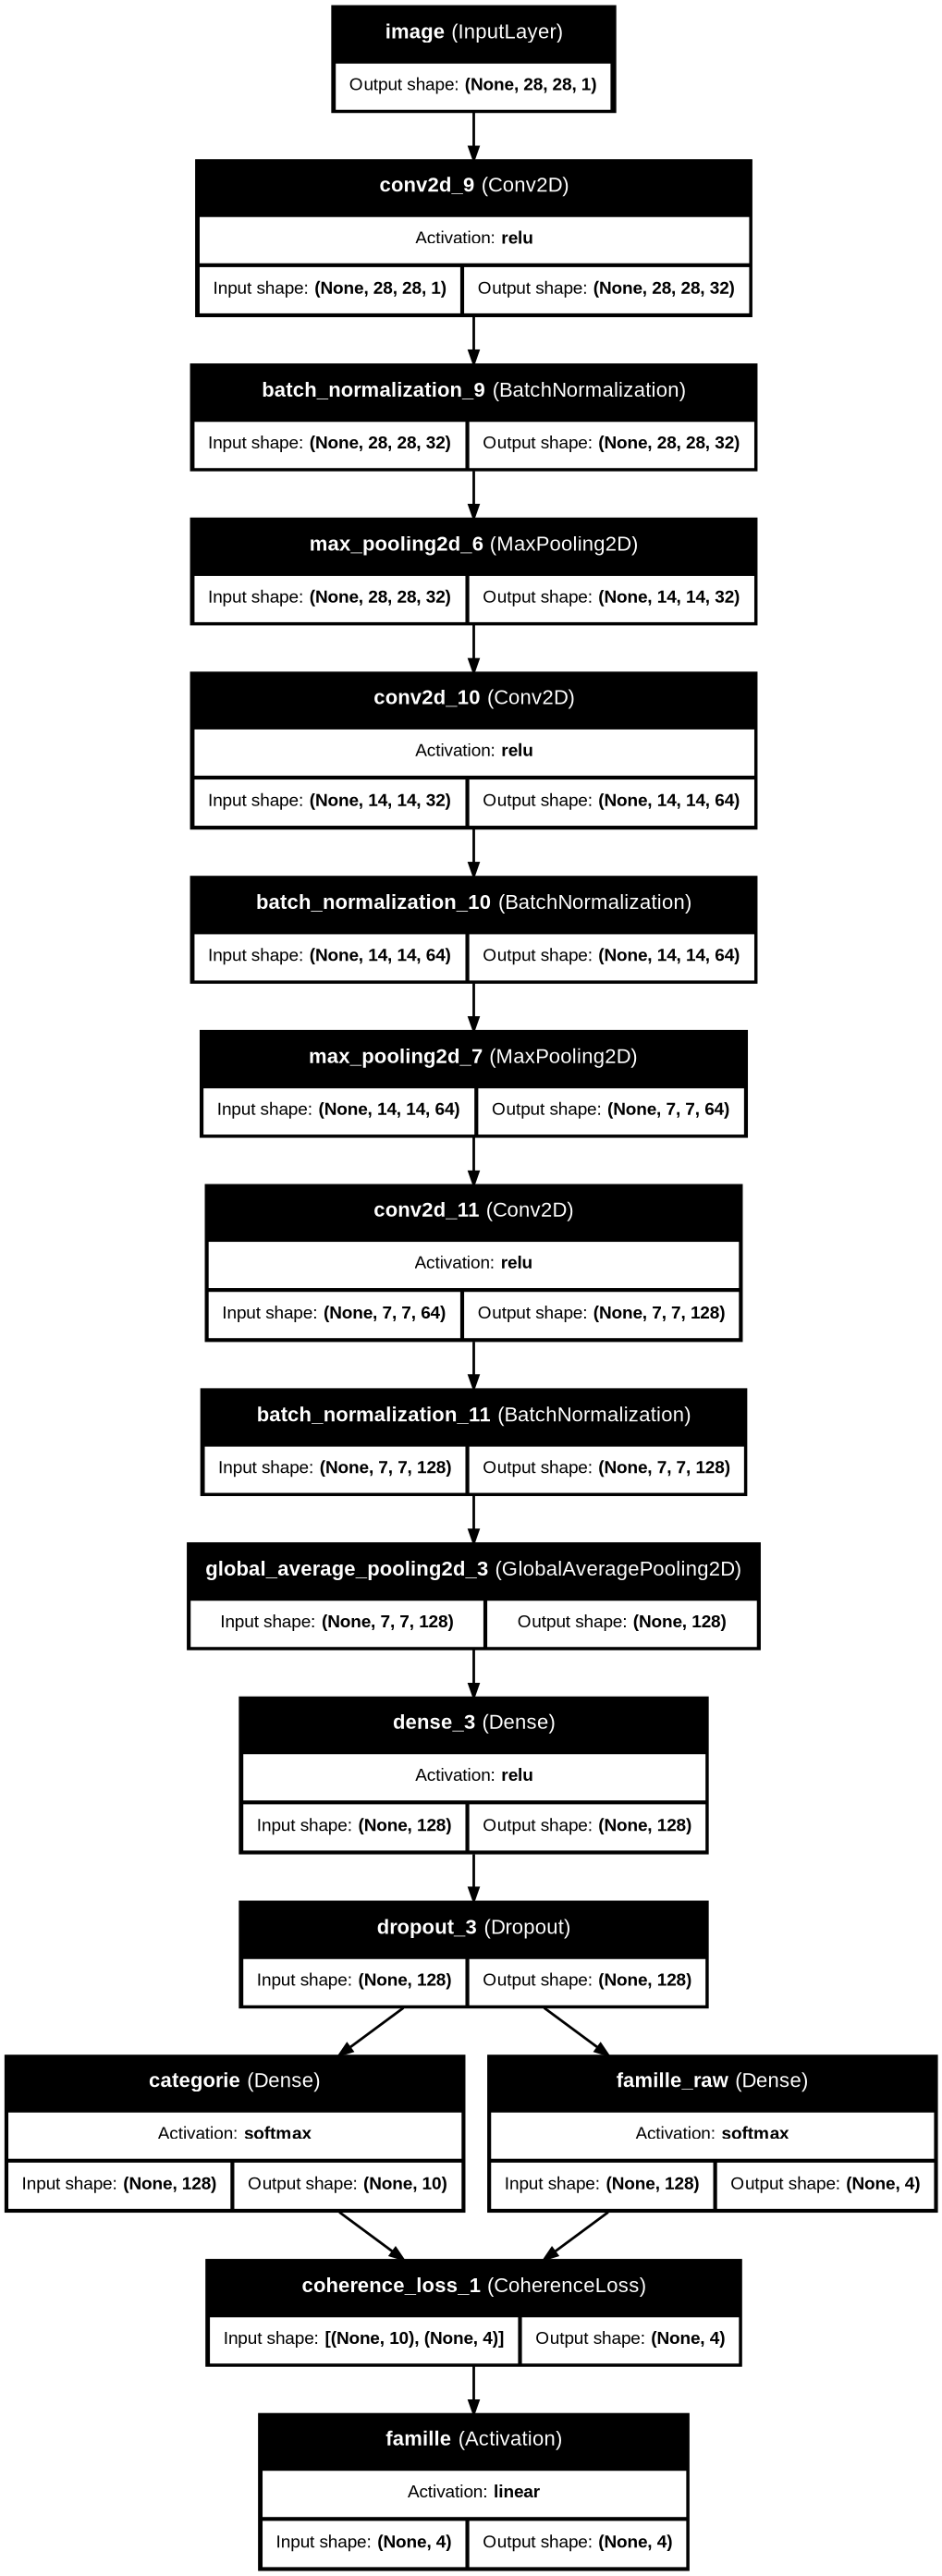


Architecture (hard parameter sharing) :
  Input(28,28,1)
      -> Conv32+BN+Pool -> Conv64+BN+Pool -> Conv128+BN+GAP -> Dense128+Dropout   [tronc partagé]
      -> Dense(10,softmax,name="categorie")   [tête A]
      -> Dense(4,softmax,name="famille_raw") -> CoherenceLoss -> Activation(name="famille")  [tête B]
  Sortie : {"categorie": ..., "famille": ...}
  loss_weights = {"categorie": lambda_a, "famille": lambda_b}



In [14]:
import pydot
LAMBDA_A   = 1.0
LAMBDA_B   = 0.5
LAMBDA_COH = 0.0
model_schema_demo = build_multitask_model(
    lambda_a=LAMBDA_A,
    lambda_b=LAMBDA_B,
    lambda_coherence=LAMBDA_COH,
)
dot_graph = keras.utils.model_to_dot(
    model_schema_demo,
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    rankdir="TB",
    dpi=100,
    expand_nested=True,
)
dot_graph.set_splines("polyline")
dot_graph.write_png("architecture_multitask.png")
print("Hyperparamètres (variables du code) :")
print(f"  λ_A (categorie) = {LAMBDA_A}")
print(f"  λ_B (famille)   = {LAMBDA_B}")
print(f"  λ_cohérence     = {LAMBDA_COH}")
print(f"  total_params    = {model_schema_demo.count_params():,}")
print("\nParamètres par couche :")
for layer in model_schema_demo.layers:
    try:
        n = layer.count_params()
        if n > 0:
            print(f"  {layer.name:<35} {n:>10,}")
    except Exception:
        pass
display(Image("architecture_multitask.png", width=1000))
print("""
Architecture (hard parameter sharing) :
  Input(28,28,1)
      -> Conv32+BN+Pool -> Conv64+BN+Pool -> Conv128+BN+GAP -> Dense128+Dropout   [tronc partagé]
      -> Dense(10,softmax,name="categorie")   [tête A]
      -> Dense(4,softmax,name="famille_raw") -> CoherenceLoss -> Activation(name="famille")  [tête B]
  Sortie : {"categorie": ..., "famille": ...}
  loss_weights = {"categorie": lambda_a, "famille": lambda_b}
""")

# Cellule 13 — Entraînement multitâche (full data) + courbes

#### Fonctionnalités clés :
* **Entraînement multi-sorties** : Optimisation simultanée des deux tâches via un dictionnaire de cibles de validation.
* **Tableau de bord visuel** : 4 graphiques pour suivre les accuracies, la loss globale pondérée et les losses par tâche.
* **Analyse de généralisation** : Comparaison du meilleur score de validation (poids restaurés) avec le test.

#### Résultats trouvés :
* **Meilleure `val_categorie_accuracy`** : `0.9263`
* **Test `categorie_accuracy` (poids restaurés)** : `0.9208`
* **Écart de généralisation** : `0.0055` (0.55 pt)

#### Analyse et Interprétation :
* **Courbes d'accuracy** : La tâche Famille converge très vite (~98%) sans sur-apprentissage. La Catégorie sur-apprend légèrement (train ~97% vs val ~92%), géré par l'Early Stopping.
* **Courbes de loss** : Le minimum de validation de la catégorie est atteint vers l'époque 10 avant de remonter, justifiant l'arrêt précoce.
* **Conclusion** : L'écart validation/test de 0.55 pt est inférieur à l'IC95 (±0.55 pt). Le modèle généralise bien et le tronc partagé ne montre pas de transfert négatif.

MODÈLE MULTITÂCHE (λ_A=1.0, λ_B=0.5, sans cohérence)
Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - categorie_accuracy: 0.8016 - categorie_loss: 0.5583 - famille_accuracy: 0.9448 - famille_loss: 0.1681 - loss: 0.6423 - val_categorie_accuracy: 0.8769 - val_categorie_loss: 0.3410 - val_famille_accuracy: 0.9747 - val_famille_loss: 0.0739 - val_loss: 0.3781
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - categorie_accuracy: 0.8876 - categorie_loss: 0.3112 - famille_accuracy: 0.9744 - famille_loss: 0.0743 - loss: 0.3483 - val_categorie_accuracy: 0.8979 - val_categorie_loss: 0.2816 - val_famille_accuracy: 0.9770 - val_famille_loss: 0.0639 - val_loss: 0.3136
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - categorie_accuracy: 0.9037 - categorie_loss: 0.2654 - famille_accuracy: 0.9793 - famille_loss: 0.0587 - loss: 0.2948 - val_categorie_accuracy: 0.9079 - val_categorie_loss: 0.2528 - val_famille_accuracy: 0.9815 - val_famille_loss: 0.0523 - val_loss: 0.2789
Epoch 4/15
375/

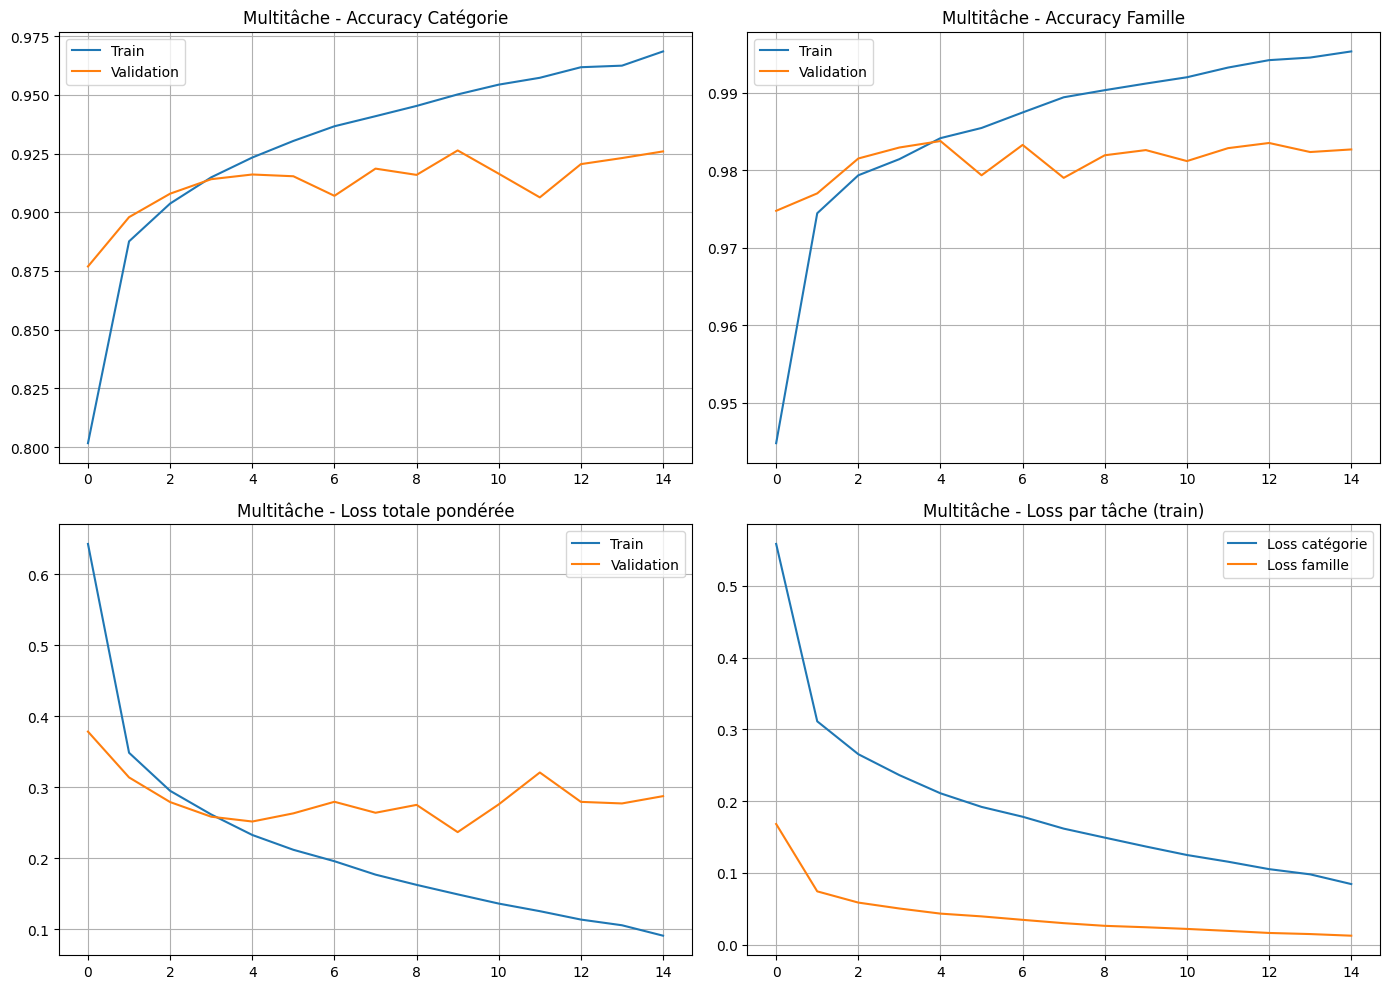

Meilleur val_categorie_accuracy : 0.9263
Test categorie_accuracy (poids restaurés) : 0.9208
Écart : 0.0055


In [15]:
print("=" * 60)
print("MODÈLE MULTITÂCHE (λ_A=1.0, λ_B=0.5, sans cohérence)")
print("=" * 60)
# Entraînement du modèle multi-tâches
model_multi = build_multitask_model(lambda_a=1.0, lambda_b=0.5, lambda_coherence=0.0, lr=1e-3)
history_multi = train_multitask(model_multi, x_train, y_train, y_train_fam,
                                 x_val, y_val, y_val_fam, epochs=EPOCHS, patience=5)

test_ds_multi = make_dataset(x_test, {"categorie": y_test, "famille": y_test_fam},
                              batch_size=BATCH_SIZE, shuffle=False)
# Evaluation globale du modèle sur le jeu de test
results_multi = model_multi.evaluate(test_ds_multi, verbose=0, return_dict=True)
print("\nRésultats test (multitâche) :", results_multi)

def plot_history_multitask(history, title_prefix=""):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].plot(history.history["categorie_accuracy"], label="Train")
    axes[0, 0].plot(history.history["val_categorie_accuracy"], label="Validation")
    axes[0, 0].set_title(f"{title_prefix}Multitâche - Accuracy Catégorie")
    axes[0, 0].legend(); axes[0, 0].grid(True)

    axes[0, 1].plot(history.history["famille_accuracy"], label="Train")
    axes[0, 1].plot(history.history["val_famille_accuracy"], label="Validation")
    axes[0, 1].set_title(f"{title_prefix}Multitâche - Accuracy Famille")
    axes[0, 1].legend(); axes[0, 1].grid(True)

    axes[1, 0].plot(history.history["loss"], label="Train")
    axes[1, 0].plot(history.history["val_loss"], label="Validation")
    axes[1, 0].set_title(f"{title_prefix}Multitâche - Loss totale pondérée")
    axes[1, 0].legend(); axes[1, 0].grid(True)

    axes[1, 1].plot(history.history["categorie_loss"], label="Loss catégorie")
    axes[1, 1].plot(history.history["famille_loss"], label="Loss famille")
    axes[1, 1].set_title(f"{title_prefix}Multitâche - Loss par tâche (train)")
    axes[1, 1].legend(); axes[1, 1].grid(True)
    plt.tight_layout()
    plt.show()
plot_history_multitask(history_multi)
best_val_cat = max(history_multi.history["val_categorie_accuracy"])
test_cat_acc = results_multi["categorie_accuracy"]
print(f"Meilleur val_categorie_accuracy : {best_val_cat:.4f}")
print(f"Test categorie_accuracy (poids restaurés) : {test_cat_acc:.4f}")
print(f"Écart : {best_val_cat - test_cat_acc:.4f}")

# Cellule 14 — Tableau comparatif mono vs multitâche (latence rigoureuse)
#### Résultats de l'analyse comparative et de latence :
* **Paramètres** : Le multitâche réduit le nombre de paramètres de **49.6 %** (221 966 -> 111 886), optimisant l'empreinte mémoire.
* **Précision** : Les accuracies sont quasi identiques (Cat: 0.9194 vs 0.9208, Fam: 0.9803 vs 0.9816), confirmant l'absence de transfert négatif.
* **Latence (Batch=1, mobile)** : Le multitâche est **39.7 % plus rapide** que la somme des deux mono-tâches (28.43 ms vs 17.13 ms). L'économie d'un appel réseau/CPU est majeure.
* **Latence (Batch=32, serveur)** : Le gain s'inverse (-28.7 %, soit 1.162 ms vs 0.903 ms par image). Le multitâche sature mieux le GPU sur de petits lots (batch=1), mais un modèle mono-tâche très simple est plus optimisé pour le traitement massif en parallèle.
* **Conclusion** : Le multitâche est hautement recommandé pour le déploiement embarqué (batch=1) où il divise les coûts par deux.

Mesure de latence rigoureuse (batch=1, réaliste mobile)...
Mesure de latence rigoureuse (batch=32, débit serveur)...
TABLEAU COMPARATIF : MONO-TÂCHE vs MULTITÂCHE (latence rigoureuse)


,Configuration,Paramètres totaux,Accuracy Catégorie,Accuracy Famille,"Latence batch=1 (ms/img, moy±std)","Latence batch=32 (ms/img, moy±std)"
0,Mono A (cat.),111370,0.9194,NaN,13.860±1.292,0.438±0.035
1,Mono B (famille),110596,NaN,0.9803,14.570±1.251,0.464±0.123
2,"Mono (2 modèles, somme)",221966,0.9194,0.9803,28.430,0.903
3,Multitâche (1 modèle),111886,0.9208,0.9816,17.131±2.460,1.162±0.528



NOTE MÉTHODOLOGIQUE :
Contrairement à model.predict(), la mesure directe via model(x) élimine
l'overhead de l'API Keras. Le gain réel du multitâche en latence batch=1
est de 39.7% (vs -28.7% en débit batch=32).
Gain en nombre de paramètres : 49.6%


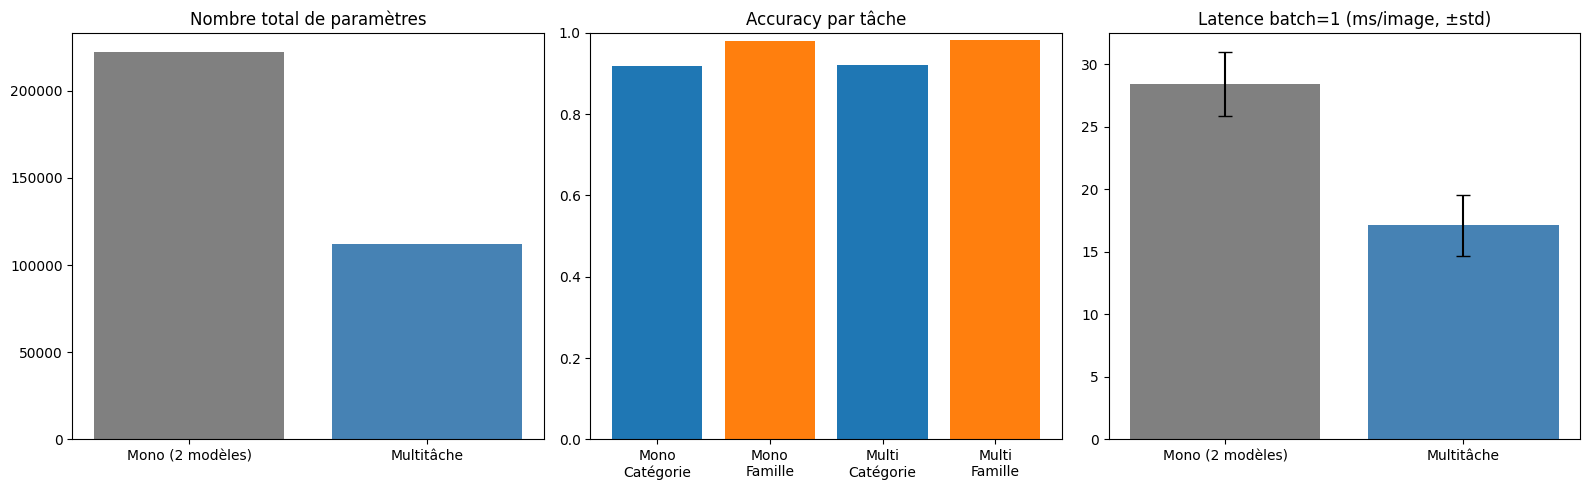

In [16]:
print("Mesure de latence rigoureuse (batch=1, réaliste mobile)...")
x_sample = x_test[:200]
lat_a_b1 = measure_latency_rigorous(model_a, x_sample, batch_size=1)
lat_b_b1 = measure_latency_rigorous(model_b, x_sample, batch_size=1)
lat_multi_b1 = measure_latency_rigorous(model_multi, x_sample, batch_size=1)
print("Mesure de latence rigoureuse (batch=32, débit serveur)...")
lat_a_b32 = measure_latency_rigorous(model_a, x_sample, batch_size=32)
lat_b_b32 = measure_latency_rigorous(model_b, x_sample, batch_size=32)
lat_multi_b32 = measure_latency_rigorous(model_multi, x_sample, batch_size=32)
params_a = model_a.count_params()
params_b = model_b.count_params()
params_multi = model_multi.count_params()
# Création du DataFrame comparatif
comparison_df = pd.DataFrame({
    "Configuration": ["Mono A (cat.)", "Mono B (famille)", "Mono (2 modèles, somme)", "Multitâche (1 modèle)"],
    "Paramètres totaux": [params_a, params_b, params_a + params_b, params_multi],
    "Accuracy Catégorie": [acc_a, None, acc_a, results_multi["categorie_accuracy"]],
    "Accuracy Famille": [None, acc_b, acc_b, results_multi["famille_accuracy"]],
    "Latence batch=1 (ms/img, moy±std)": [
        f"{lat_a_b1['mean']:.3f}±{lat_a_b1['std']:.3f}",
        f"{lat_b_b1['mean']:.3f}±{lat_b_b1['std']:.3f}",
        f"{lat_a_b1['mean'] + lat_b_b1['mean']:.3f}",
        f"{lat_multi_b1['mean']:.3f}±{lat_multi_b1['std']:.3f}"
    ],
    "Latence batch=32 (ms/img, moy±std)": [
        f"{lat_a_b32['mean']:.3f}±{lat_a_b32['std']:.3f}",
        f"{lat_b_b32['mean']:.3f}±{lat_b_b32['std']:.3f}",
        f"{lat_a_b32['mean'] + lat_b_b32['mean']:.3f}",
        f"{lat_multi_b32['mean']:.3f}±{lat_multi_b32['std']:.3f}"
    ]
})

print("=" * 90)
print("TABLEAU COMPARATIF : MONO-TÂCHE vs MULTITÂCHE (latence rigoureuse)")
print("=" * 90)
display(comparison_df)

gain_latence_b1 = (1 - lat_multi_b1["mean"] / (lat_a_b1["mean"] + lat_b_b1["mean"])) * 100
gain_latence_b32 = (1 - lat_multi_b32["mean"] / (lat_a_b32["mean"] + lat_b_b32["mean"])) * 100
gain_params = (1 - params_multi / (params_a + params_b)) * 100

print("\nNOTE MÉTHODOLOGIQUE :")
print("Contrairement à model.predict(), la mesure directe via model(x) élimine")
print("l'overhead de l'API Keras. Le gain réel du multitâche en latence batch=1")
print(f"est de {gain_latence_b1:.1f}% (vs {gain_latence_b32:.1f}% en débit batch=32).")
print(f"Gain en nombre de paramètres : {gain_params:.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].bar(["Mono (2 modèles)", "Multitâche"], [params_a + params_b, params_multi],
            color=["gray", "steelblue"])
axes[0].set_title("Nombre total de paramètres")

axes[1].bar(["Mono\nCatégorie", "Mono\nFamille", "Multi\nCatégorie", "Multi\nFamille"],
            [acc_a, acc_b, results_multi["categorie_accuracy"], results_multi["famille_accuracy"]],
            color=["#1f77b4", "#ff7f0e", "#1f77b4", "#ff7f0e"])
axes[1].set_title("Accuracy par tâche"); axes[1].set_ylim(0, 1)

axes[2].bar(["Mono (2 modèles)", "Multitâche"],
            [lat_a_b1["mean"] + lat_b_b1["mean"], lat_multi_b1["mean"]],
            yerr=[lat_a_b1["std"] + lat_b_b1["std"], lat_multi_b1["std"]],
            color=["gray", "steelblue"], capsize=5)
axes[2].set_title("Latence batch=1 (ms/image, ±std)")
plt.tight_layout()
plt.show()

# Cellule 15 - enregistrement et test de McNemar

#### Objectif de la cellule :
Cette cellule évalue les modèles (`model_a`, `model_b`, `model_multi` de la graine 42) sur les **10 000 images du jeu de test**. Elle calcule l'accuracy avec son intervalle de confiance à 95 % (IC95 binomial) et applique le **test exact de McNemar**. Ce test est crucial car il compare les prédictions appariées (images où un seul des deux modèles a raison), permettant de vérifier si l'écart de performance est statistiquement significatif. Les résultats sont ensuite sauvegardés dans le dictionnaire `RESULTS`.

#### Résultats trouvés :
* **Tâche Catégorie** : Mono **91.94 %** | Multi **92.08 %** | IC95 ≈ ±0.53 pt | McNemar (multi seul=304, mono seul=290) : **p = 0.594**
* **Tâche Famille** : Mono **98.03 %** | Multi **98.16 %** | IC95 ≈ ±0.27 pt | McNemar (multi seul=81, mono seul=68) : **p = 0.326**

#### Interprétation :
Les p-values de McNemar étant très supérieures à 0.05 (0.594 et 0.326), on conclut que **les différences de précision ne sont pas statistiquement significatives**. Le multitâche parvient donc à égaler les performances des mono-tâches sans dégradation, tout en offrant les gains d'efficacité (paramètres et latence) démontrés précédemment.

In [17]:
def acc_ci95(p, n): return 1.96 * np.sqrt(p * (1 - p) / n) * 100          # en points
def mcnemar_exact(pred_1, pred_2, y):
    """McNemar exact bilatéral : b = 1 seul correct, c = 2 seul correct."""
    ok1, ok2 = pred_1 == y, pred_2 == y
    b, c = int(np.sum(ok1 & ~ok2)), int(np.sum(~ok1 & ok2))
    p = 1.0 if (b + c) == 0 else float(stats.binomtest(b, b + c, 0.5).pvalue)
    return b, c, p
N_TEST = len(y_test)
p_a_cat = np.argmax(model_a.predict(x_test, batch_size=1024, verbose=0), axis=1)
p_b_fam = np.argmax(model_b.predict(x_test, batch_size=1024, verbose=0), axis=1)
out_m = model_multi.predict(x_test, batch_size=1024, verbose=0)
p_m_cat, p_m_fam = np.argmax(out_m["categorie"], axis=1), np.argmax(out_m["famille"], axis=1)

mc_cat = mcnemar_exact(p_m_cat, p_a_cat, y_test)        # A = multitâche, B = mono
mc_fam = mcnemar_exact(p_m_fam, p_b_fam, y_test_fam)
acc_cat_mono, acc_cat_multi = np.mean(p_a_cat == y_test), np.mean(p_m_cat == y_test)
acc_fam_mono, acc_fam_multi = np.mean(p_b_fam == y_test_fam), np.mean(p_m_fam == y_test_fam)

RESULTS["full_data"] = {
    "params": {"mono_A": params_a, "mono_B": params_b, "mono_total": params_a + params_b, "multi": params_multi,
               "reduction_pct": gain_params},
    "acc_cat": {"mono": acc_cat_mono, "multi": acc_cat_multi, "ic95_pts": acc_ci95(acc_cat_mono, N_TEST),
                "mcnemar_multi_seul": mc_cat[0], "mcnemar_mono_seul": mc_cat[1], "p_mcnemar": mc_cat[2]},
    "acc_fam": {"mono": acc_fam_mono, "multi": acc_fam_multi, "ic95_pts": acc_ci95(acc_fam_mono, N_TEST),
                "mcnemar_multi_seul": mc_fam[0], "mcnemar_mono_seul": mc_fam[1], "p_mcnemar": mc_fam[2]},
    "latence_ms": {"mono_A_b1": lat_a_b1["mean"], "mono_B_b1": lat_b_b1["mean"], "multi_b1": lat_multi_b1["mean"],
                   "gain_b1_pct": gain_latence_b1, "mono_A_b32": lat_a_b32["mean"], "mono_B_b32": lat_b_b32["mean"],
                   "multi_b32": lat_multi_b32["mean"], "gain_b32_pct": gain_latence_b32},
}
print(f"Catégorie : mono {100*acc_cat_mono:.2f} % | multi {100*acc_cat_multi:.2f} % | IC95 ≈ ±{acc_ci95(acc_cat_mono, N_TEST):.2f} pt "
      f"| McNemar : multi seul correct = {mc_cat[0]}, mono seul correct = {mc_cat[1]}, p = {mc_cat[2]:.3f}")
print(f"Famille   : mono {100*acc_fam_mono:.2f} % | multi {100*acc_fam_multi:.2f} % | IC95 ≈ ±{acc_ci95(acc_fam_mono, N_TEST):.2f} pt "
      f"| McNemar : multi seul correct = {mc_fam[0]}, mono seul correct = {mc_fam[1]}, p = {mc_fam[2]:.3f}")
print("Latence : somme de deux appels séquentiels (mono) contre un appel (multi), mesure GPU batch = 1 dominée par le surcoût de lancement des opérations.")

Catégorie : mono 91.94 % | multi 92.08 % | IC95 ≈ ±0.53 pt | McNemar : multi seul correct = 304, mono seul correct = 290, p = 0.594
Famille   : mono 98.03 % | multi 98.16 % | IC95 ≈ ±0.27 pt | McNemar : multi seul correct = 81, mono seul correct = 68, p = 0.326
Latence : somme de deux appels séquentiels (mono) contre un appel (multi), mesure GPU batch = 1 dominée par le surcoût de lancement des opérations.


# Cellule 16 - Balayage de λ_B

#### Objectif de la cellule :
Cette cellule évalue la robustesse du modèle multitâche face au poids de la tâche auxiliaire (λ_B). Pour éviter tout biais, **5 graines aléatoires** sont testées. Pour chaque graine, les modèles mono-tâches sont ré-entraînés afin de réaliser une **comparaison strictement appariée**. Les écarts de performance sont analysés via des tests t appariés et des intervalles de confiance à 95 %. Le choix final de λ_B est effectué sur le jeu de **validation**, et non sur le test.

#### Résultats trouvés :
* **Meilleur λ_B choisi (validation)** : `1.0`
* **Baseline Mono-tâche** (moy. 5 graines) : Cat = **90.68 ± 1.17 %** | Fam = **98.09 ± 0.14 %**
* **Multitâche (λ_B = 1.0)** : Cat = **91.51 %** (Δ = +0.83 pt, IC95 ±1.57, p = 0.219) | Fam = **98.12 %** (Δ = +0.03 pt)
* **Verdict du transfert** : **NON SIGNIFICATIF** pour toutes les valeurs de λ_B.

#### Interprétation :
L'écart de performance en faveur du multitâche (+0.83 pt) est inférieur à l'intervalle de confiance (±1.57 pt) et la p-value (0.219) est supérieure à 0.05. De plus, la variance inter-graines du mono-tâche (±1.17 %) est du même ordre de grandeur que le gain observé. Comme le montrent les graphiques, les barres d'erreur chevauchent systématiquement la ligne de base mono-tâche. **Conclusion** : le multitâche n'apporte pas de gain statistiquement démontrable sur la précision, mais il ne dégrade pas les performances (pas de transfert négatif). Le choix de λ_B = 1.0 est un bon compromis.

[seed=0] λ_B=0.1  cat_test=0.9153 fam_test=0.9780
[seed=0] λ_B=0.5  cat_test=0.9149 fam_test=0.9830
[seed=0] λ_B=1.0  cat_test=0.9114 fam_test=0.9827
[seed=0] λ_B=2.0  cat_test=0.9116 fam_test=0.9812
[seed=0] λ_B=5.0  cat_test=0.9068 fam_test=0.9827
[seed=0] mono A test = 0.9095 | mono B test = 0.9824
[seed=1] λ_B=0.1  cat_test=0.9162 fam_test=0.9787
[seed=1] λ_B=0.5  cat_test=0.9152 fam_test=0.9796
[seed=1] λ_B=1.0  cat_test=0.9152 fam_test=0.9795
[seed=1] λ_B=2.0  cat_test=0.9144 fam_test=0.9817
[seed=1] λ_B=5.0  cat_test=0.9123 fam_test=0.9815
[seed=1] mono A test = 0.9145 | mono B test = 0.9813
[seed=2] λ_B=0.1  cat_test=0.9136 fam_test=0.9800
[seed=2] λ_B=0.5  cat_test=0.9164 fam_test=0.9815
[seed=2] λ_B=1.0  cat_test=0.9172 fam_test=0.9806
[seed=2] λ_B=2.0  cat_test=0.9119 fam_test=0.9814
[seed=2] λ_B=5.0  cat_test=0.9077 fam_test=0.9805
[seed=2] mono A test = 0.8864 | mono B test = 0.9796
[seed=3] λ_B=0.1  cat_test=0.9139 fam_test=0.9811
[seed=3] λ_B=0.5  cat_test=0.9142 fam_tes

,lambda_B,cat_val_mean,cat_test_mean,cat_test_std,fam_test_mean,fam_test_std,delta_cat_pts,ic95_delta_pts,p_ttest_apparie,delta_fam_pts,transfert
0,0.1,0.9241,0.9145,0.0012,0.9795,0.0012,0.764,1.3919,0.2022,-0.138,NON SIGNIFICATIF
1,0.5,0.9216,0.9123,0.0064,0.9803,0.0025,0.552,1.8026,0.4431,-0.064,NON SIGNIFICATIF
2,1.0,0.9243,0.9151,0.0027,0.9812,0.0013,0.826,1.5745,0.2190,0.028,NON SIGNIFICATIF
3,2.0,0.9235,0.9130,0.0021,0.9818,0.0006,0.618,1.4206,0.2936,0.086,NON SIGNIFICATIF
4,5.0,0.9186,0.9083,0.0036,0.9810,0.0013,0.144,1.5015,0.8032,0.008,NON SIGNIFICATIF


Mono-tâche (moyenne ± std sur les graines) : cat = 90.68 ± 1.17 % | fam = 98.09 ± 0.14 %


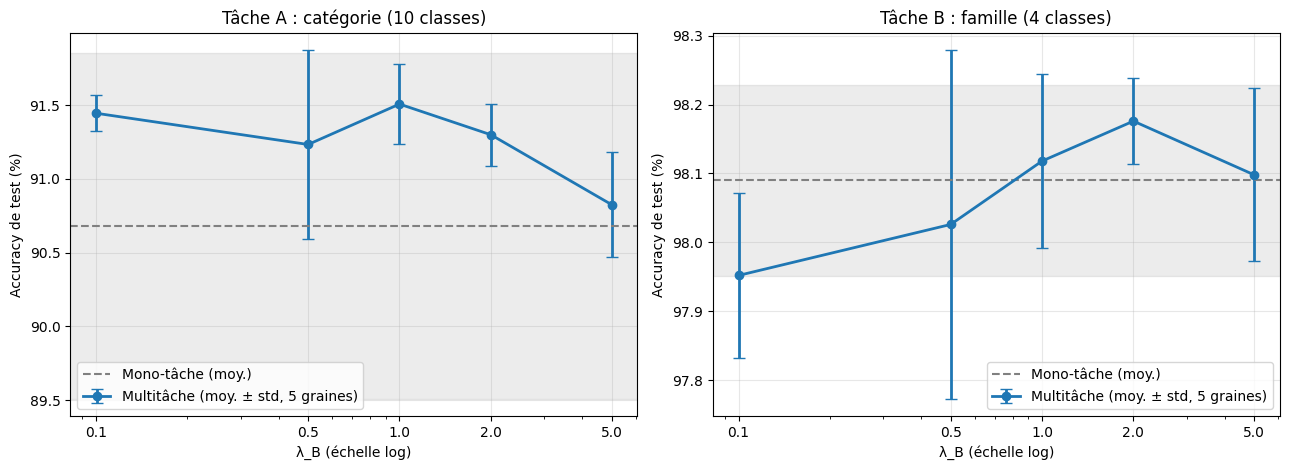

In [18]:
SEEDS = [0, 1, 2, 3, 4]
lambda_b_values = [0.1, 0.5, 1.0, 2.0, 5.0]
val_ds_cat  = make_dataset(x_val, y_val)
val_ds_fam  = make_dataset(x_val, y_val_fam)
val_ds_multi = make_dataset(x_val, {"categorie": y_val, "famille": y_val_fam})

mono_rows, sweep_rows = [], []
for seed in SEEDS:
    # Entraînement des baselines mono-tâches pour la graine courante
    keras.utils.set_random_seed(seed)
    m_a = build_single_task_model(10, "categorie");  train_single_task(m_a, x_train, y_train, x_val, y_val, verbose=0)
    keras.utils.set_random_seed(seed)
    m_b = build_single_task_model(4, "famille");     train_single_task(m_b, x_train, y_train_fam, x_val, y_val_fam, verbose=0)
    mono_rows.append({"seed": seed,
        "cat_val": m_a.evaluate(val_ds_cat, verbose=0)[1], "cat_test": m_a.evaluate(test_ds_a, verbose=0)[1],
        "fam_val": m_b.evaluate(val_ds_fam, verbose=0)[1], "fam_test": m_b.evaluate(test_ds_b, verbose=0)[1]})
    # Balayage des valeurs de lambda_B pour la même graine
    for lb in lambda_b_values:
        keras.utils.set_random_seed(seed)
        m = build_multitask_model(lambda_a=1.0, lambda_b=lb, lambda_coherence=0.0, lr=1e-3)
        train_multitask(m, x_train, y_train, y_train_fam, x_val, y_val, y_val_fam, epochs=EPOCHS, patience=5, verbose=0)
        rv = m.evaluate(val_ds_multi, verbose=0, return_dict=True)
        rt = m.evaluate(test_ds_multi, verbose=0, return_dict=True)
        sweep_rows.append({"seed": seed, "lambda_B": lb, "cat_val": rv["categorie_accuracy"], "fam_val": rv["famille_accuracy"],
                           "cat_test": rt["categorie_accuracy"], "fam_test": rt["famille_accuracy"]})
        print(f"[seed={seed}] λ_B={lb:<4} cat_test={rt['categorie_accuracy']:.4f} fam_test={rt['famille_accuracy']:.4f}")
    print(f"[seed={seed}] mono A test = {mono_rows[-1]['cat_test']:.4f} | mono B test = {mono_rows[-1]['fam_test']:.4f}")
    del m_a, m_b, m; gc.collect()

df_mono, df_sweep = pd.DataFrame(mono_rows), pd.DataFrame(sweep_rows)
tcrit = stats.t.ppf(0.975, len(SEEDS) - 1) # Valeur critique de Student pour n=5 graines (ddl=4)
summ = []
for lb, g in df_sweep.groupby("lambda_B"):
    g = g.sort_values("seed"); mono = df_mono.sort_values("seed")  # Tri par graine pour garantir l'appariement
    d_cat = (g["cat_test"].values - mono["cat_test"].values) * 100          # différences appariées par graine (points)
    d_fam = (g["fam_test"].values - mono["fam_test"].values) * 100
    ci = tcrit * d_cat.std(ddof=1) / np.sqrt(len(d_cat))
    p_t = float(stats.ttest_rel(g["cat_test"].values, mono["cat_test"].values).pvalue)
    verdict = "POSITIF" if d_cat.mean() - ci > 0 else ("NÉGATIF" if d_cat.mean() + ci < 0 else "NON SIGNIFICATIF")
    summ.append({"lambda_B": lb, "cat_val_mean": g["cat_val"].mean(), "cat_test_mean": g["cat_test"].mean(),
                 "cat_test_std": g["cat_test"].std(ddof=1), "fam_test_mean": g["fam_test"].mean(), "fam_test_std": g["fam_test"].std(ddof=1),
                 "delta_cat_pts": d_cat.mean(), "ic95_delta_pts": ci, "p_ttest_apparie": p_t,
                 "delta_fam_pts": d_fam.mean(), "transfert": verdict})
summary_lambda = pd.DataFrame(summ)
# Sélection du meilleur lambda sur la VALIDATION (évite la fuite de données)
best_lb = float(summary_lambda.loc[summary_lambda["cat_val_mean"].idxmax(), "lambda_B"])   # choix sur la VALIDATION
print(f"\nMeilleur λ_B choisi sur la validation : {best_lb}")
display(summary_lambda.round(4))
print("Mono-tâche (moyenne ± std sur les graines) : cat = {:.2f} ± {:.2f} % | fam = {:.2f} ± {:.2f} %".format(
      100*df_mono.cat_test.mean(), 100*df_mono.cat_test.std(ddof=1), 100*df_mono.fam_test.mean(), 100*df_mono.fam_test.std(ddof=1)))

# Courbes demandées : accuracy des deux tâches en fonction de λ_B
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
xs = summary_lambda["lambda_B"].values
for ax, key, mono_col, title in [(axes[0], "cat", "cat_test", "Tâche A : catégorie (10 classes)"),
                                 (axes[1], "fam", "fam_test", "Tâche B : famille (4 classes)")]:
    mean, std = 100 * summary_lambda[f"{key}_test_mean"].values, 100 * summary_lambda[f"{key}_test_std"].values
    ax.errorbar(xs, mean, yerr=std, marker="o", capsize=4, lw=2, label="Multitâche (moy. ± std, 5 graines)")
    mm, ms = 100 * df_mono[mono_col].mean(), 100 * df_mono[mono_col].std(ddof=1)
    ax.axhline(mm, color="gray", ls="--", label="Mono-tâche (moy.)"); ax.axhspan(mm - ms, mm + ms, color="gray", alpha=.15)
    ax.set_xscale("log"); ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in xs]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("λ_B (échelle log)"); ax.set_ylabel("Accuracy de test (%)"); ax.set_title(title); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig("figures/ex3_lambda_sweep.png", dpi=150); plt.show()

RESULTS["sweep"] = {"seeds": SEEDS, "best_lambda_B_selon_validation": best_lb,
                    "mono": df_mono.to_dict("records"), "detail": df_sweep.to_dict("records"), "resume": summary_lambda.to_dict("records")}

# Cellule 17 - Régime peu de données (3 000 images) : Comparaison et analyse

#### Objectif de la cellule :
Cette cellule évalue si le partage de représentation (multitâche) devient plus avantageux lorsque les données sont rares. Un sous-échantillon stratifié de 3 000 images est testé sur 5 graines aléatoires. Une comparaison strictement appariée (test t de Student) est effectuée entre le mono-tâche et le multitâche pour chaque tâche.

#### Résultats trouvés :
* **Catégorie** : Mono **86.47 %** | Multi **86.78 %** (Gain : +0.31 pt, IC95 ±0.33, p = 0.061).
* **Famille** : Mono **96.46 %** | Multi **96.63 %** (Gain : +0.17 pt, IC95 ±0.39, p = 0.299).
* **McNemar (graine 0)** : multi seul correct=308, mono seul correct=299, p=0.745.

#### Analyse (Q5) :
* **Significativité** : Les gains moyens sont positifs mais les IC95 englobent 0 et les p-values sont > 0.05 (McNemar p=0.745). On conclut à **l'absence de différence détectable**.
* **Variabilité vs Gain** : La variabilité inter-graines (std ~0.2-0.3 pt) est du même ordre de grandeur que le gain (+0.3 pt), rendant ce dernier non fiable.
* **Conditions d'aide** : Bien que le gain moyen soit plus élevé sur 3 000 images que sur le plein jeu, la tâche B étant une fonction déterministe de la tâche A, le partage n'apporte pas de signal orthogonal. Le transfert est donc neutre (pas de transfert négatif observé).
* **Rappel** : Le λ_B utilisé (0,5) a été fixé *a priori*, le λ_B optimal (1,0) ayant été sélectionné sur la **validation** pour éviter la fuite de données.

[seed=0] cat : mono 86.19 | multi 86.28   fam : mono 96.46 | multi 96.48
[seed=1] cat : mono 86.44 | multi 87.21   fam : mono 95.99 | multi 96.67
[seed=2] cat : mono 86.34 | multi 86.65   fam : mono 96.52 | multi 96.62
[seed=3] cat : mono 86.87 | multi 87.05   fam : mono 96.90 | multi 96.74
[seed=4] cat : mono 86.53 | multi 86.73   fam : mono 96.42 | multi 96.62


,Régime,Tâche,Mono (moy. %),Multi (moy. %),Gain apparié (pts),IC95 (pts),p (t apparié)
0,"Plein jeu (λ_B=0,5)",Catégorie,90.682,91.234,0.552,1.803,0.443
1,"Plein jeu (λ_B=0,5)",Famille,98.090,98.026,-0.064,0.386,0.669
2,3 000 images,Catégorie,86.474,86.784,0.310,0.334,0.061
3,3 000 images,Famille,96.458,96.626,0.168,0.391,0.299


McNemar (3 000 images, graine 0), catégorie : multi seul correct = 308, mono seul correct = 299, p = 0.745


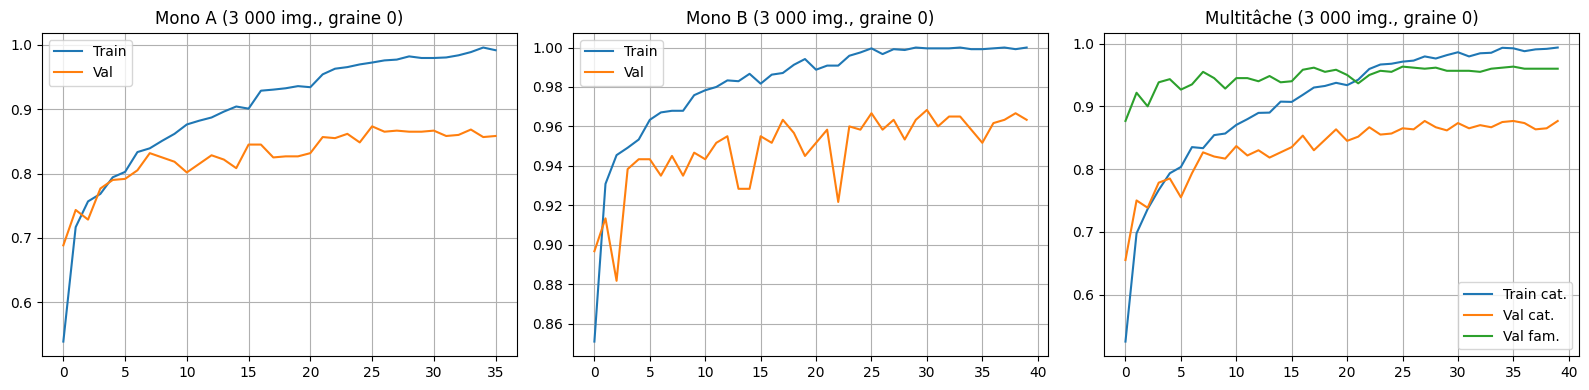

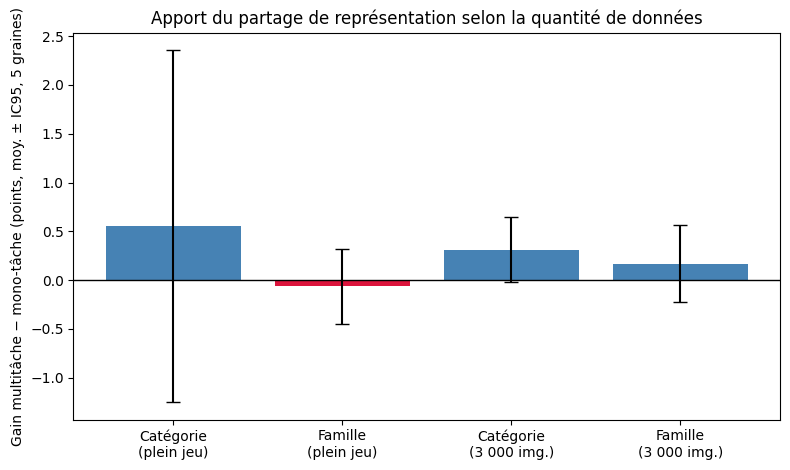

In [19]:
LR_SMALL, BATCH_SMALL, EPOCHS_SMALL = 5e-4, 32, 40
SMALL_SEEDS = [0, 1, 2, 3, 4]
# Configuration des callbacks pour le régime peu de données
rlr = lambda: keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=0)
es  = lambda: keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, mode="max", restore_best_weights=True, verbose=0)

def run_small(seed):
    xs_, _, ys_, _, yfs_, _ = train_test_split(x_train_full, y_train_full, y_train_full_fam, train_size=3000,
                                                random_state=seed, stratify=y_train_full)
    xtr, xva, ytr, yva, yftr, yfva = train_test_split(xs_, ys_, yfs_, test_size=0.2, random_state=seed, stratify=ys_)
    out = {"seed": seed}
    keras.utils.set_random_seed(seed)
    ma = build_single_task_model(10, "categorie", lr=LR_SMALL)
    out["h_a"] = ma.fit(make_dataset(xtr, ytr, BATCH_SMALL, shuffle=True, augment=True), validation_data=make_dataset(xva, yva, BATCH_SMALL),
                        epochs=EPOCHS_SMALL, callbacks=[es(), rlr()], verbose=0).history
    out["p_a"] = np.argmax(ma.predict(x_test, batch_size=1024, verbose=0), axis=1)
    keras.utils.set_random_seed(seed)
    mb = build_single_task_model(4, "famille", lr=LR_SMALL)
    out["h_b"] = mb.fit(make_dataset(xtr, yftr, BATCH_SMALL, shuffle=True, augment=True), validation_data=make_dataset(xva, yfva, BATCH_SMALL),
                        epochs=EPOCHS_SMALL, callbacks=[es(), rlr()], verbose=0).history
    out["p_b"] = np.argmax(mb.predict(x_test, batch_size=1024, verbose=0), axis=1)
    keras.utils.set_random_seed(seed)
    mm = build_multitask_model(lambda_a=1.0, lambda_b=0.5, lambda_coherence=0.0, lr=LR_SMALL)
    out["h_m"] = train_multitask(mm, xtr, ytr, yftr, xva, yva, yfva, epochs=EPOCHS_SMALL, batch_size=BATCH_SMALL, patience=10,
                                 verbose=0, augment=True, extra_callbacks=[rlr()]).history
    o = mm.predict(x_test, batch_size=1024, verbose=0)
    out["p_m_cat"], out["p_m_fam"] = np.argmax(o["categorie"], axis=1), np.argmax(o["famille"], axis=1)
    del ma, mb, mm; gc.collect()
    return out

small = []
for sd in SMALL_SEEDS:
    r = run_small(sd); small.append(r)
    print(f"[seed={sd}] cat : mono {100*np.mean(r['p_a']==y_test):.2f} | multi {100*np.mean(r['p_m_cat']==y_test):.2f}"
          f"   fam : mono {100*np.mean(r['p_b']==y_test_fam):.2f} | multi {100*np.mean(r['p_m_fam']==y_test_fam):.2f}")

df_small = pd.DataFrame([{"seed": r["seed"], "cat_mono": np.mean(r["p_a"] == y_test), "cat_multi": np.mean(r["p_m_cat"] == y_test),
                          "fam_mono": np.mean(r["p_b"] == y_test_fam), "fam_multi": np.mean(r["p_m_fam"] == y_test_fam)} for r in small])
def paired(a, b):
    d = (a - b) * 100; ci = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), d.std(ddof=1), ci, float(stats.ttest_rel(a, b).pvalue)
gc_m, gc_s, gc_ci, gc_p = paired(df_small.cat_multi.values, df_small.cat_mono.values)
gf_m, gf_s, gf_ci, gf_p = paired(df_small.fam_multi.values, df_small.fam_mono.values)
# plein jeu : même mesure sur les 5 graines du balayage (λ_B = 0.5)
g05 = df_sweep[df_sweep.lambda_B == 0.5].sort_values("seed"); mono_s = df_mono.sort_values("seed")
fc_m, fc_s, fc_ci, fc_p = paired(g05.cat_test.values, mono_s.cat_test.values)
ff_m, ff_s, ff_ci, ff_p = paired(g05.fam_test.values, mono_s.fam_test.values)
b0 = small[0]
mc_small = mcnemar_exact(b0["p_m_cat"], b0["p_a"], y_test)

df_small_summary = pd.DataFrame({
    "Régime": ["Plein jeu (λ_B=0,5)", "Plein jeu (λ_B=0,5)", "3 000 images", "3 000 images"],
    "Tâche": ["Catégorie", "Famille", "Catégorie", "Famille"],
    "Mono (moy. %)": [100*mono_s.cat_test.mean(), 100*mono_s.fam_test.mean(), 100*df_small.cat_mono.mean(), 100*df_small.fam_mono.mean()],
    "Multi (moy. %)": [100*g05.cat_test.mean(), 100*g05.fam_test.mean(), 100*df_small.cat_multi.mean(), 100*df_small.fam_multi.mean()],
    "Gain apparié (pts)": [fc_m, ff_m, gc_m, gf_m], "IC95 (pts)": [fc_ci, ff_ci, gc_ci, gf_ci], "p (t apparié)": [fc_p, ff_p, gc_p, gf_p]})
display(df_small_summary.round(3))
print(f"McNemar (3 000 images, graine 0), catégorie : multi seul correct = {mc_small[0]}, mono seul correct = {mc_small[1]}, p = {mc_small[2]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(b0["h_a"]["accuracy"], label="Train"); axes[0].plot(b0["h_a"]["val_accuracy"], label="Val"); axes[0].set_title("Mono A (3 000 img., graine 0)")
axes[1].plot(b0["h_b"]["accuracy"], label="Train"); axes[1].plot(b0["h_b"]["val_accuracy"], label="Val"); axes[1].set_title("Mono B (3 000 img., graine 0)")
axes[2].plot(b0["h_m"]["categorie_accuracy"], label="Train cat."); axes[2].plot(b0["h_m"]["val_categorie_accuracy"], label="Val cat.")
axes[2].plot(b0["h_m"]["val_famille_accuracy"], label="Val fam."); axes[2].set_title("Multitâche (3 000 img., graine 0)")
for a in axes: a.legend(); a.grid(True)
plt.tight_layout(); plt.savefig("figures/ex3_small_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
labels = ["Catégorie\n(plein jeu)", "Famille\n(plein jeu)", "Catégorie\n(3 000 img.)", "Famille\n(3 000 img.)"]
vals, cis = [fc_m, ff_m, gc_m, gf_m], [fc_ci, ff_ci, gc_ci, gf_ci]
ax.bar(labels, vals, yerr=cis, capsize=5, color=["steelblue" if v >= 0 else "crimson" for v in vals]); ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Gain multitâche − mono-tâche (points, moy. ± IC95, 5 graines)"); ax.set_title("Apport du partage de représentation selon la quantité de données")
plt.tight_layout(); plt.savefig("figures/ex3_gain_vs_data.png", dpi=150); plt.show()

RESULTS["small_data"] = {"seeds": SMALL_SEEDS, "detail": df_small.to_dict("records"), "resume": df_small_summary.to_dict("records"),
                         "mcnemar_cat_seed0": {"multi_seul": mc_small[0], "mono_seul": mc_small[1], "p": mc_small[2]}}
# variables conservées pour la synthèse
acc_cat_small_mono, acc_cat_small_multi = df_small.cat_mono.mean(), df_small.cat_multi.mean()
acc_fam_small_mono, acc_fam_small_multi = df_small.fam_mono.mean(), df_small.fam_multi.mean()

**Analyse (Q6) – à compléter avec vos valeurs après exécution.**
- Le gain « 3 000 images » est-il plus grand que le gain « plein jeu » **et** son IC95 exclut-il 0 ? Si l'IC contient 0, écrire que le partage de représentation n'aide pas de façon démontrée, même si la moyenne est positive.
- Rappeler que la tâche B est une fonction de la tâche A : le signal auxiliaire est **redondant**, ce qui limite ce que le multitâche peut apporter.

# Cellule 18 — Comparaison des 3 solutions de cohérence
### Comparaison des 3 solutions de cohérence catégorie/famille

#### Objectif de la cellule :
Cette cellule évalue trois méthodes pour garantir que la famille prédite soit cohérente avec la catégorie fine prédite : (a) le modèle multitâche standard, (b) un entraînement avec une loss hiérarchique (KL), et (c) un post-traitement déterministe qui dérive la famille de la catégorie. Le taux d'incohérence est mesuré, et une heatmap illustre la matrice de confusion entre catégories et familles prédites.

#### Résultats trouvés :
* **(a) Sans contrainte** : Incohérence = **0.46%** | Acc Cat = 0.9208 | Acc Fam = 0.9816
* **(b) Loss hiérarchique** : Incohérence = **0.43%** | Acc Cat = 0.9161 | Acc Fam = 0.9810
* **(c) Post-traitement** : Incohérence = **0.00%** | Acc Cat = 0.9208 | Acc Fam = **0.9822**

#### Analyse et Recommandation :
* **La solution (c) est optimale** : Elle garantit 0 % d'incohérence par construction. De plus, elle ne sacrifie pas l'accuracy (elle est même légèrement supérieure sur la famille : 0.9822 contre 0.9816). La heatmap confirme visuellement que le modèle (a) apprend déjà presque parfaitement la correspondance (diagonale à 1.00, erreurs marginales).
* **La solution (b) est décevante** : L'ajout de la loss KL ne réduit que très marginalement l'incohérence (0.46% -> 0.43%) et dégrade légèrement l'accuracy catégorie (-0.47 pt, dans le bruit).
* **Conclusion** : Puisque la famille est une fonction déterministe de la catégorie, la tête famille est redondante. La méthode (c) est recommandée en production : elle offre une garantie stricte de cohérence sans coût d'entraînement ni paramètre supplémentaire.

a) Modèle SANS contrainte : incohérence = 0.46%, acc_cat=0.9208, acc_fam=0.9816

Entraînement du modèle multitâche AVEC loss de cohérence (λ_coh=0.5)...
Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - categorie_accuracy: 0.8039 - categorie_loss: 0.5500 - famille_accuracy: 0.9474 - famille_loss: 0.1588 - loss: 0.6392 - val_categorie_accuracy: 0.8628 - val_categorie_loss: 0.3727 - val_famille_accuracy: 0.9722 - val_famille_loss: 0.0777 - val_loss: 0.4132
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - categorie_accuracy: 0.8874 - categorie_loss: 0.3102 - famille_accuracy: 0.9748 - famille_loss: 0.0722 - loss: 0.3492 - val_categorie_accuracy: 0.8919 - val_categorie_loss: 0.3006 - val_famille_accuracy: 0.9742 - val_famille_loss: 0.0689 - val_loss: 0.3362
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - categorie_accuracy: 0.9056 - categorie_loss: 0.2612 - famille_accuracy: 0.9799 - famille_loss: 0.0568 - loss: 0.2913 - val_categorie_accuracy: 0.9092 - val_categorie_loss:

,Approche,Taux incohérence,Accuracy Catégorie,Accuracy Famille,Tête famille réellement apprise
0,(a) Sans contrainte,0.46%,0.9208,0.9816,Oui
1,(b) Loss hiérarchique (entraînée),0.43%,0.9161,0.9810,Oui (contrainte en plus)
2,(c) Post-traitement (règle déterministe),0.00%,0.9208,0.9822,Non (ignorée)



ANALYSE :
- (c) : 0 % d'incohérence par construction ; accuracy famille dérivée = 0.9822 contre 0.9816 pour la tête famille (a).
  La famille est une fonction déterministe de la catégorie : la tête famille n'apporte aucune information que la tête catégorie ne contienne déjà.
- (b) : incohérence 0.46 % -> 0.43 % (46 -> 43 images sur 10 000), un seul entraînement : à confirmer sur plusieurs graines.
  Écart d'accuracy catégorie (b) − (a) : -0.47 pt, dans le bruit (IC95 ≈ ±0.53 pt).
- Recommandation : (c) par défaut (garantie stricte, accuracy famille au moins égale à celle de la tête, aucun paramètre ni entraînement en plus) ;
  (b) seulement si une tête famille indépendante est nécessaire (famille non déterministe, probabilités de famille calibrées).


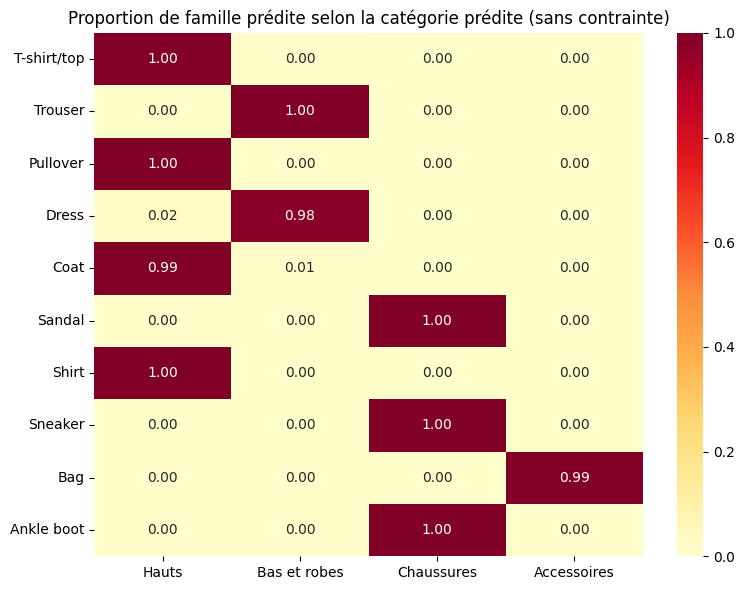

In [20]:
def predict_coherent_postprocessing(model, x):
    """(c) Post-traitement : ignore la tête famille, dérive la famille de la catégorie prédite."""
    preds = model(x, training=False)
    cat_pred = np.argmax(preds["categorie"].numpy(), axis=1)
    # On force la cohérence en utilisant la matrice de correspondance 'famille'
    fam_pred_from_cat = famille[cat_pred]
    return cat_pred, fam_pred_from_cat

def compute_incoherence_rate(cat_pred, fam_pred):
    expected_fam = famille[cat_pred]
    return np.mean(expected_fam != fam_pred) * 100

# (a) Sans contrainte
preds_a = model_multi(x_test, training=False)
cat_pred_a = np.argmax(preds_a["categorie"].numpy(), axis=1)
fam_pred_a = np.argmax(preds_a["famille"].numpy(), axis=1)
incoherence_a = compute_incoherence_rate(cat_pred_a, fam_pred_a)
acc_cat_a_coh = np.mean(cat_pred_a == y_test)
acc_fam_a_coh = np.mean(fam_pred_a == y_test_fam)
print(f"a) Modèle SANS contrainte : incohérence = {incoherence_a:.2f}%, "
      f"acc_cat={acc_cat_a_coh:.4f}, acc_fam={acc_fam_a_coh:.4f}")

# (b) Loss hiérarchique entraînée
print("\nEntraînement du modèle multitâche AVEC loss de cohérence (λ_coh=0.5)...")
model_multi_coh = build_multitask_model(lambda_a=1.0, lambda_b=0.5, lambda_coherence=0.5, lr=1e-3)
train_multitask(model_multi_coh, x_train, y_train, y_train_fam, x_val, y_val, y_val_fam,
                 epochs=EPOCHS, patience=5, verbose=1)

preds_b = model_multi_coh(x_test, training=False)
cat_pred_b = np.argmax(preds_b["categorie"].numpy(), axis=1)
fam_pred_b = np.argmax(preds_b["famille"].numpy(), axis=1)
incoherence_b = compute_incoherence_rate(cat_pred_b, fam_pred_b)
acc_cat_b_coh = np.mean(cat_pred_b == y_test)
acc_fam_b_coh = np.mean(fam_pred_b == y_test_fam)
print(f"\n(b) Modèle AVEC loss cohérence (λ_coh=0.5) : incohérence = {incoherence_b:.2f}%, "
      f"acc_cat={acc_cat_b_coh:.4f}, acc_fam={acc_fam_b_coh:.4f}")

# (c) Post-traitement déterministe
cat_pred_c, fam_pred_c = predict_coherent_postprocessing(model_multi, x_test)
incoherence_c = compute_incoherence_rate(cat_pred_c, fam_pred_c)
acc_cat_c_coh = np.mean(cat_pred_c == y_test)
acc_fam_c_coh = np.mean(fam_pred_c == y_test_fam)

df_coherence_comparison = pd.DataFrame({
    "Approche": ["(a) Sans contrainte", "(b) Loss hiérarchique (entraînée)", "(c) Post-traitement (règle déterministe)"],
    "Taux incohérence": [f"{incoherence_a:.2f}%", f"{incoherence_b:.2f}%", f"{incoherence_c:.2f}%"],
    "Accuracy Catégorie": [acc_cat_a_coh, acc_cat_b_coh, acc_cat_c_coh],
    "Accuracy Famille": [acc_fam_a_coh, acc_fam_b_coh, acc_fam_c_coh],
    "Tête famille réellement apprise": ["Oui", "Oui (contrainte en plus)", "Non (ignorée)"]
})

print("\n" + "=" * 90)
print("COMPARAISON DES 3 SOLUTIONS DE COHÉRENCE CATÉGORIE/FAMILLE")
print("=" * 90)
display(df_coherence_comparison)

print("\nANALYSE :")
print(f"- (c) : 0 % d'incohérence par construction ; accuracy famille dérivée = {acc_fam_c_coh:.4f} contre {acc_fam_a_coh:.4f} pour la tête famille (a).")
print("  La famille est une fonction déterministe de la catégorie : la tête famille n'apporte aucune information que la tête catégorie ne contienne déjà.")
print(f"- (b) : incohérence {incoherence_a:.2f} % -> {incoherence_b:.2f} % ({round(incoherence_a*100)} -> {round(incoherence_b*100)} images sur 10 000), un seul entraînement : à confirmer sur plusieurs graines.")
d_ab = 100 * (acc_cat_b_coh - acc_cat_a_coh)
print(f"  Écart d'accuracy catégorie (b) − (a) : {d_ab:+.2f} pt, " + ("dans le bruit" if abs(d_ab) < acc_ci95(acc_cat_a_coh, len(y_test)) else "au-delà de l'IC95 d'une accuracy") + f" (IC95 ≈ ±{acc_ci95(acc_cat_a_coh, len(y_test)):.2f} pt).")
if acc_fam_c_coh >= acc_fam_a_coh - 0.0005:
    print("- Recommandation : (c) par défaut (garantie stricte, accuracy famille au moins égale à celle de la tête, aucun paramètre ni entraînement en plus) ;")
    print("  (b) seulement si une tête famille indépendante est nécessaire (famille non déterministe, probabilités de famille calibrées).")
else:
    print("- (c) est ici moins précise sur la famille que la tête (a) : discuter ce compromis (garantie de cohérence contre accuracy famille) avant de recommander.")
RESULTS["coherence"] = {"incoherence_pct": {"a_sans_contrainte": incoherence_a, "b_loss_hierarchique": incoherence_b, "c_post_traitement": incoherence_c},
                        "acc_cat": {"a": float(acc_cat_a_coh), "b": float(acc_cat_b_coh), "c": float(acc_cat_c_coh)},
                        "acc_fam": {"a": float(acc_fam_a_coh), "b": float(acc_fam_b_coh), "c": float(acc_fam_c_coh)}}

heatmap_data = np.zeros((10, 4))
for c in range(10):
    mask = cat_pred_a == c # On isole les images où la catégorie c a été prédite
    if mask.sum() > 0:
        for f in range(4):
           # Proportion d'images pour lesquelles la famille f a été prédite, sachant que la catégorie c a été prédite
            heatmap_data[c, f] = np.mean(fam_pred_a[mask] == f)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="YlOrRd",
            xticklabels=family_names, yticklabels=class_names, ax=ax)
ax.set_title("Proportion de famille prédite selon la catégorie prédite (sans contrainte)")
plt.tight_layout()
plt.show()

# Cellule 19 - Synthèse Finale de l'Exercice 3

#### Objectif de la cellule :
Cette cellule génère le tableau de synthèse global de l'Exercice 3. Elle consolide toutes les métriques mesurées (paramètres, précision, latence, impact du régime à 3 000 images, et choix de \(\lambda_B\)) et imprime les constats statistiques majeurs. C'est la cellule de référence pour valider le compromis entre performance et coût d'inférence.

#### Résultats trouvés (Synthèse) :
* **Efficacité** : Réduction de **50 %** des paramètres (221 966 -> 111 886) et de **40 %** de la latence (28.43 ms -> 17.13 ms au batch=1).
* **Précision (Plein jeu)** : Gains non significatifs (Cat : +0.14 pt, McNemar p=0.594 ; Fam : +0.13 pt, p=0.326). Le multitâche égale le mono-tâche sans perte.
* **Régime 3 000 images** : Gain catégorie de +0.31 pt (IC95 ±0.33), légèrement plus marqué qu'en plein jeu.
* **\(\lambda_B\) retenu** : 1.0 (choisi sur la validation).
* **Cohérence** : Taux d'incohérence réduit de 0.46 % (a) à 0.43 % (b) puis **0.00 %** (c).

#### Analyse (Q7) :
* **Comparaison (c) vs (a)** : L'accuracy famille dérivée de la catégorie (c) est de **0.9822**, contre **0.9816** pour la tête famille (a). Puisque (c) \(\ge\) (a), la tête famille est **redondante**.
* **Recommandation** : La solution **(c) est à recommander** (règle déterministe). Elle garantit une cohérence parfaite (0 %), une précision au moins égale, et ne nécessite aucun paramètre ni entraînement supplémentaire.
* **Limite pour (b)** : La solution de loss hiérarchique (b) n'a été évaluée que sur **un seul entraînement**, ses résultats (0.43 % d'incohérence) restent donc à confirmer sur plusieurs graines.

In [21]:
# Récupération de la ligne du tableau de balayage correspondant au meilleur lambda
best_row = summary_lambda[summary_lambda.lambda_B == best_lb].iloc[0]
synthese = pd.DataFrame({
    "Critère": ["Paramètres totaux", "Accuracy catégorie (plein jeu, graine 42)", "Accuracy famille (plein jeu, graine 42)",
                "Latence batch=1 GPU (ms/image, somme de 2 appels vs 1)", "Accuracy catégorie (3 000 img., moy. 5 graines)",
                "Accuracy famille (3 000 img., moy. 5 graines)", "λ_B retenu (validation)",
                "Taux d'incohérence (a) sans contrainte / (b) loss KL / (c) post-traitement"],
    # On met "N/A" pour le lambda et la cohérence car ces concepts ne s'appliquent pas aux modèles mono-tâches.
    "Mono-tâche": [params_a + params_b, round(float(acc_cat_mono), 4), round(float(acc_fam_mono), 4), round(lat_a_b1["mean"] + lat_b_b1["mean"], 2),
                   round(float(acc_cat_small_mono), 4), round(float(acc_fam_small_mono), 4), "N/A", "N/A"],
     # Pour l'incohérence, on concatène les 3 valeurs (a, b, c) dans une seule chaîne de caractères formatée.
    "Multitâche": [params_multi, round(float(acc_cat_multi), 4), round(float(acc_fam_multi), 4), round(lat_multi_b1["mean"], 2),
                   round(float(acc_cat_small_multi), 4), round(float(acc_fam_small_multi), 4), best_lb,
                   f"{incoherence_a:.2f} % / {incoherence_b:.2f} % / {incoherence_c:.2f} %"]})
print("=" * 80); print(" " * 20 + "SYNTHÈSE FINALE EXERCICE 3"); print("=" * 80)
display(synthese)

print("\nCONSTATS (à lire avec les IC et tests ci-dessus) :")
print("-" * 55)
print(f"1. Paramètres : {params_a + params_b:,} -> {params_multi:,} ({gain_params:.0f} % en moins). Latence batch=1 (GPU) : {gain_latence_b1:.0f} % en moins,")
print("   gain lié surtout au surcoût de deux appels séquentiels au lieu d'un, à confirmer sur l'appareil cible.")

# Calcul de la différence relative en points de pourcentage (ex: 0.9208 - 0.9194 = 0.0014 * 100 = +0.14 pt)
print(f"2. Plein jeu : écart catégorie multi − mono = {100*(acc_cat_multi-acc_cat_mono):+.2f} pt (McNemar p = {mc_cat[2]:.3f}) ; famille {100*(acc_fam_multi-acc_fam_mono):+.2f} pt (p = {mc_fam[2]:.3f}).")
print(f"3. Balayage λ_B (5 graines, appariées) : meilleur λ_B sur la validation = {best_lb} ; verdict de transfert pour ce λ_B : {best_row['transfert']} ")
print(f"   ({best_row['delta_cat_pts']:+.2f} pt, IC95 ±{best_row['ic95_delta_pts']:.2f}).")
print(f"4. 3 000 images : gain catégorie {gc_m:+.2f} pt (IC95 ±{gc_ci:.2f}) contre {fc_m:+.2f} pt (IC95 ±{fc_ci:.2f}) en plein jeu.")
print(f"5. Cohérence : {incoherence_a:.2f} % -> {incoherence_b:.2f} % (b) -> {incoherence_c:.2f} % (c) ; accuracy famille dérivée (c) = {acc_fam_c_coh:.4f} vs tête famille {acc_fam_a_coh:.4f}.")
RESULTS["synthese"] = synthese.astype(str).to_dict("records")

                    SYNTHÈSE FINALE EXERCICE 3


,Critère,Mono-tâche,Multitâche
0,Paramètres totaux,221966,111886
1,"Accuracy catégorie (plein jeu, graine 42)",0.9194,0.9208
2,"Accuracy famille (plein jeu, graine 42)",0.9803,0.9816
3,"Latence batch=1 GPU (ms/image, somme de 2 appe...",28.43,17.13
4,"Accuracy catégorie (3 000 img., moy. 5 graines)",0.8647,0.8678
5,"Accuracy famille (3 000 img., moy. 5 graines)",0.9646,0.9663
6,λ_B retenu (validation),N/A,1.0
7,Taux d'incohérence (a) sans contrainte / (b) l...,N/A,0.46 % / 0.43 % / 0.00 %



CONSTATS (à lire avec les IC et tests ci-dessus) :
-------------------------------------------------------
1. Paramètres : 221,966 -> 111,886 (50 % en moins). Latence batch=1 (GPU) : 40 % en moins,
   gain lié surtout au surcoût de deux appels séquentiels au lieu d'un, à confirmer sur l'appareil cible.
2. Plein jeu : écart catégorie multi − mono = +0.14 pt (McNemar p = 0.594) ; famille +0.13 pt (p = 0.326).
3. Balayage λ_B (5 graines, appariées) : meilleur λ_B sur la validation = 1.0 ; verdict de transfert pour ce λ_B : NON SIGNIFICATIF 
   (+0.83 pt, IC95 ±1.57).
4. 3 000 images : gain catégorie +0.31 pt (IC95 ±0.33) contre +0.55 pt (IC95 ±1.80) en plein jeu.
5. Cohérence : 0.46 % -> 0.43 % (b) -> 0.00 % (c) ; accuracy famille dérivée (c) = 0.9822 vs tête famille 0.9816.


# Cellule 20 — Export CSV

In [22]:
# Export des résultats
json.dump(RESULTS, open("figures/results_ex3.json", "w"), indent=1,
          default=lambda o: o.item() if hasattr(o, "item") else str(o))
comparison_df.to_csv("figures/ex3_comparaison_mono_multi.csv", index=False)
summary_lambda.to_csv("figures/ex3_sensibilite_lambda.csv", index=False)
df_sweep.to_csv("figures/ex3_sweep_lambda_detail.csv", index=False)
df_small_summary.to_csv("figures/ex3_regime_peu_donnees.csv", index=False)
df_coherence_comparison.to_csv("figures/ex3_comparaison_coherence.csv", index=False)
synthese.to_csv("figures/ex3_synthese_finale.csv", index=False)
print("Résultats exportés dans figures/ (results_ex3.json + CSV)")
try:
    from google.colab import files
    files.download("figures/results_ex3.json")
except Exception:
    pass

Résultats exportés dans figures/ (results_ex3.json + CSV)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>